# PROYECTO BIG DATA: ARQUITECTURA MEDALLION EN DATABRICKS
## Análisis de accidentes de tránsito en Colombia — Vehículos involucrados (Ley 2251 de 2022)

**Autoras:** Laura C. Arboleda (CC 1007286582) · Ana M. Echeverri (CC 1036627870) · **Plataforma:** Databricks (Unity Catalog + Delta Lake + PySpark)

---

### 1. Descripción de la arquitectura implementada

Se implementa el patrón **Medallion**, que organiza el dato en tres capas de calidad y valor progresivo:

| Capa | Tabla | Rol | Formato |
| --- | --- | --- | --- |
| **Bronze** | `workspace.laura_arboleda6582.accidentalidad_bronze` | Dato crudo tal como llega del CSV, **sin modificaciones**, con metadatos de trazabilidad (fecha de ingesta y archivo de origen) | Delta |
| **Silver** | `workspace.laura_arboleda6582.accidentalidad_silver` | Dato limpio: tipos corregidos, formatos estandarizados, duplicados exactos depurados (con copia de auditoría), columnas derivadas de calidad | Delta |
| **Gold** | `accidentalidad_gold` (+ 2 tablas analíticas) | Dato agregado listo para análisis de accidentalidad vial: indicadores por departamento, municipio, tiempo, tipo de vehículo, marca y gravedad | Delta |

**Principios del diseño:**
* El CSV original en el volumen **nunca se modifica**; Bronze conserva todos los registros originales.
* Cada capa se construye **solo** a partir de la capa anterior (Bronze → Silver → Gold).
* **Protección de datos existentes:** ninguna tabla existente se sobrescribe. Cada tabla se crea **solo si no existe**; si ya existe, la escritura se omite y se solicita autorización explícita antes de cualquier reemplazo. Las tablas ajenas al proyecto (p. ej. `yield_trials`) y el CSV original del volumen **jamás se modifican**.
* Los registros problemáticos no se eliminan silenciosamente: los duplicados depurados se conservan en una tabla de auditoría y los valores ambiguos se marcan/nulan dejando el original intacto en Bronze.

**Fuente:** `/Volumes/workspace/laura_arboleda6582/vehiculos_involucrados_en_un_accidente_de_transito/` (archivo CSV de ~48,4 MB, 450.335 registros y 9 columnas a nivel de vehículo involucrado en un accidente).

In [0]:
# ============================================================
# 0. CONFIGURACIÓN GLOBAL DEL PROYECTO
# ============================================================
# Se centralizan rutas y nombres de tablas para que el proceso sea
# reproducible y fácil de mantener (buena práctica de ingeniería de datos).

from pyspark.sql import functions as F

RUTA_VOLUMEN = "/Volumes/workspace/laura_arboleda6582/vehiculos_involucrados_en_un_accidente_de_transito"
CATALOGO     = "workspace"
ESQUEMA      = "laura_arboleda6582"

# Tablas de la arquitectura Medallion (Unity Catalog + Delta Lake)
TABLA_BRONZE       = f"{CATALOGO}.{ESQUEMA}.accidentalidad_bronze"
TABLA_SILVER       = f"{CATALOGO}.{ESQUEMA}.accidentalidad_silver"
TABLA_SILVER_DUPES = f"{CATALOGO}.{ESQUEMA}.accidentalidad_silver_duplicados_auditoria"
TABLA_GOLD         = f"{CATALOGO}.{ESQUEMA}.accidentalidad_gold"
TABLA_GOLD_MARCAS  = f"{CATALOGO}.{ESQUEMA}.accidentalidad_gold_marcas"
TABLA_GOLD_TEND    = f"{CATALOGO}.{ESQUEMA}.accidentalidad_gold_tendencia"

TODAS_LAS_TABLAS = [TABLA_BRONZE, TABLA_SILVER, TABLA_SILVER_DUPES,
                    TABLA_GOLD, TABLA_GOLD_MARCAS, TABLA_GOLD_TEND]

# Columnas de negocio originales del CSV (clave para trazabilidad y deduplicación)
COLS_NEGOCIO = ["MARCA_VEHICULO", "MODELO_VEHICULO", "TIPO_VEHICULO", "EDAD_VEHICULO",
                "FECHA_ACCIDENTE", "GRAVEDAD_ACCIDENTE", "DEPARTAMENTO_ACCIDENTE",
                "MUNICIPIO_ACCIDENTE", "AUTORIDAD_DE_TRANSITO"]

# POLÍTICA DE ESCRITURA (regla del proyecto): NINGUNA tabla existente
# se sobrescribe. Cada tabla se crea SOLO SI NO EXISTE; si ya existe, la
# escritura se OMITE y se solicita autorización explícita para reemplazarla.
# Las tablas ajenas al proyecto (p. ej. yield_trials) nunca se tocan, y el
# CSV original del volumen se lee en modo de solo lectura en todo el proceso.
existentes = {t.tableName for t in spark.sql(f"SHOW TABLES IN {CATALOGO}.{ESQUEMA}").collect()}
ya_creadas = [t for t in TODAS_LAS_TABLAS if t.split(".")[-1] in existentes]
if ya_creadas:
    print("ℹ️ Tablas del proyecto que YA existen (se conservan intactas; su escritura se omitirá):")
    for t in ya_creadas:
        print("  -", t)
    print("   Para reemplazar cualquiera de ellas se requiere autorización explícita.")
else:
    print("✅ Ninguna tabla del proyecto existe aún; se crearán desde cero.")

def escribir_si_no_existe(df, tabla):
    """Crea la tabla SOLO SI NO EXISTE (nunca sobrescribe).
    Devuelve True si la escribió; False si ya existía y se omitió la escritura."""
    if spark.catalog.tableExists(tabla):
        print(f"⏭️ {tabla} YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).")
        print("    Para reemplazarla se requiere autorización explícita.")
        return False
    (df.write
        .option("overwriteSchema", "true")
        .saveAsTable(tabla))
    print(f"✅ {tabla} CREADA ({spark.table(tabla).count():,} filas)")
    return True

print("\nSpark:", spark.version)
print("Configuración cargada correctamente.")

ℹ️ Tablas del proyecto que YA existen (se conservan intactas; su escritura se omitirá):
  - workspace.laura_arboleda6582.accidentalidad_bronze
  - workspace.laura_arboleda6582.accidentalidad_silver
  - workspace.laura_arboleda6582.accidentalidad_silver_duplicados_auditoria
  - workspace.laura_arboleda6582.accidentalidad_gold
  - workspace.laura_arboleda6582.accidentalidad_gold_marcas
  - workspace.laura_arboleda6582.accidentalidad_gold_tendencia
   Para reemplazar cualquiera de ellas se requiere autorización explícita.

Spark: 4.2.0
Configuración cargada correctamente.


## ETAPA 1 · EXPLORACIÓN E INGESTA — CAPA BRONZE

**Objetivo:** llevar el dato crudo del CSV a una tabla Delta gobernada por Unity Catalog, **sin alterar ningún valor**.

Pasos que ejecuta esta sección:
1. Descubrimiento automático del archivo CSV dentro del volumen (no se asume un nombre fijo).
2. Lectura con `header=True` conservando los encabezados originales; todas las columnas se leen como `string` para **no permitir que Spark infiera tipos y altere valores** (p. ej. edades con separador de miles).
3. Adición de metadatos de trazabilidad: `_fecha_ingesta` (timestamp de la carga) y `_archivo_origen` (nombre del archivo fuente).
4. Escritura a `accidentalidad_bronze` en formato Delta.
5. Verificación: conteo de registros, columnas y formato de almacenamiento.

> **Regla de oro de Bronze:** no se eliminan registros, no se corrigen valores, no se filtran filas. Bronze es la copia fiel y auditable de la fuente; cualquier depuración ocurre en Silver y siempre es trazable de vuelta.

In [0]:
# ============================================================
# 1.1 DESCUBRIMIENTO AUTOMÁTICO DEL ARCHIVO CSV
# ============================================================
# Se listan los archivos del volumen y se seleccionan los CSV.
# Si hubiese varios, se ingesta el más reciente (ninguno en este caso).

archivos = [f.path for f in dbutils.fs.ls(RUTA_VOLUMEN)]
csvs = sorted([p for p in archivos if p.lower().endswith(".csv")])

assert len(csvs) >= 1, "No se encontró ningún archivo CSV en el volumen"
ARCHIVO_CSV = csvs[-1]                       # el más reciente si hay varios
NOMBRE_ARCHIVO = ARCHIVO_CSV.split("/")[-1]
print(f"Archivos en el volumen: {len(archivos)}")
print(f"Archivo a ingerir: {NOMBRE_ARCHIVO}")

# Lectura EXPLORATORIA de una muestra para entender la estructura
df_muestra = (spark.read.option("header", True)
                      .option("inferSchema", False)   # todo string: sin alterar valores
                      .csv(ARCHIVO_CSV))

print(f"\nFilas totales: {df_muestra.count():,} | Columnas: {len(df_muestra.columns)}")
print("\nEstructura del archivo original (todas las columnas):")
df_muestra.printSchema()
display(df_muestra.limit(10))

Archivos en el volumen: 1
Archivo a ingerir: VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv

Filas totales: 450,335 | Columnas: 9

Estructura del archivo original (todas las columnas):
root
 |-- MARCA_VEHICULO: string (nullable = true)
 |-- MODELO_VEHICULO: string (nullable = true)
 |-- TIPO_VEHICULO: string (nullable = true)
 |-- EDAD_VEHICULO: string (nullable = true)
 |-- FECHA_ACCIDENTE: string (nullable = true)
 |-- GRAVEDAD_ACCIDENTE: string (nullable = true)
 |-- DEPARTAMENTO_ACCIDENTE: string (nullable = true)
 |-- MUNICIPIO_ACCIDENTE: string (nullable = true)
 |-- AUTORIDAD_DE_TRANSITO: string (nullable = true)



MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO
VOLKSWAGEN,2018,CAMION,7,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
AKT,2024,MOTOCICLETA,3,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE
YAMAHA,2022,MOTOCICLETA,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
FOTON,2022,TRACTOCAMION,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE
YAMAHA,2023,MOTOCICLETA,4,09/2026,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOyTTE BUCARAMANGA
CHERY,2017,CAMIONETA,10,09/2026,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOyTTE BUCARAMANGA
YAMAHA,2019,MOTOCICLETA,8,09/2026,CON HERIDOS,ANTIOQUIA,COPACABANA,DIRECCION DE TRANSITO Y TRANSPORTE
CHEVROLET,1981,TRACTOCAMION,46,09/2026,CON MUERTOS,BOLIVAR,ACHI,DIRECCION DE TRANSITO Y TRANSPORTE
VOLKSWAGEN,2022,TRACTOCAMION,5,09/2026,CON HERIDOS,BOLIVAR,CLEMENCIA,DIRECCION DE TRANSITO Y TRANSPORTE
BAJAJ,2022,MOTOCICLETA,4,09/2026,CON HERIDOS,BOLIVAR,CLEMENCIA,DIRECCION DE TRANSITO Y TRANSPORTE


In [0]:
# ============================================================
# 1.2 INGESTA A BRONZE: DATO CRUDO + TRAZABILIDAD
# ============================================================
# Se conservan TODOS los registros y valores originales (todo string).
# Se agregan únicamente columnas de METADATOS (prefijo '_'), que no
# forman parte del dato de negocio sino de su auditoría.

df_bronze = (spark.read
    .option("header", True)
    .option("inferSchema", False)      # sin inferencia: el dato no se altera
    .csv(ARCHIVO_CSV)
    .withColumn("_fecha_ingesta", F.current_timestamp())
    .withColumn("_archivo_origen", F.lit(NOMBRE_ARCHIVO))
)

print(f"Registros a ingerir: {df_bronze.count():,}")

# Escritura en Delta Lake (Unity Catalog): SOLO SI NO EXISTE.
# Política del proyecto: nunca se sobrescribe una tabla existente;
# si ya existe, la escritura se omite y se pide autorización explícita.
creada_bronze = escribir_si_no_existe(df_bronze, TABLA_BRONZE)

# ---- Verificación inmediata de la capa Bronze ----
df_bronze_tb = spark.table(TABLA_BRONZE)
cnt_bronze = df_bronze_tb.count()
detalle_bronze = spark.sql(f"DESCRIBE DETAIL {TABLA_BRONZE}").select("format").first()

print(f"\n✔ Tabla creada: {TABLA_BRONZE}" if creada_bronze else f"\n✔ Tabla verificada (ya existía; escritura omitida): {TABLA_BRONZE}")
print(f"  Registros: {cnt_bronze:,} (esperado: 450,335 — sin pérdidas)")
print(f"  Columnas:  {len(df_bronze_tb.columns)} (9 de negocio + 2 de trazabilidad)")
print(f"  Formato de almacenamiento: {detalle_bronze['format'].upper()}")
assert cnt_bronze == df_bronze.count(), "Pérdida de registros en Bronze"
display(df_bronze_tb.limit(5))

Registros a ingerir: 450,335
⏭️ workspace.laura_arboleda6582.accidentalidad_bronze YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.

✔ Tabla verificada (ya existía; escritura omitida): workspace.laura_arboleda6582.accidentalidad_bronze
  Registros: 450,335 (esperado: 450,335 — sin pérdidas)
  Columnas:  11 (9 de negocio + 2 de trazabilidad)
  Formato de almacenamiento: DELTA


MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO,_fecha_ingesta,_archivo_origen
VOLKSWAGEN,2018,CAMION,7,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
AKT,2024,MOTOCICLETA,3,09/2026,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
YAMAHA,2022,MOTOCICLETA,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
FOTON,2022,TRACTOCAMION,5,09/2026,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
YAMAHA,2023,MOTOCICLETA,4,09/2026,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOyTTE BUCARAMANGA,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv


## ETAPA 2 · LIMPIEZA Y TRANSFORMACIÓN — CAPA SILVER

**Objetivo:** depurar Bronze aplicando reglas de calidad **justificadas y documentadas**, sin destruir información:

1. **Perfilado:** nulos por columna, duplicados, inconsistencias de tipos/formatos, valores atípicos, coherencia temporal y geográfica.
2. **Tipos:** `MODELO_VEHICULO` y `EDAD_VEHICULO` pasan a entero; la fecha `MM/YYYY` se descompone en `ANIO`, `MES` y `FECHA` tipo `date`.
3. **Estandarización:** trim + mayúsculas en textos; el marcador de dato ausente `"SIN MARCA"` se convierte a NULL (no es una marca real; dejarlo como categoría distorsionaría los rankings de marcas).
4. **Duplicados:** se depuran SOLO los duplicados exactos en las 9 columnas de negocio, tras evaluar el patrón (ver celda 2.2). Los grupos depurados se conservan en `accidentalidad_silver_duplicados_auditoria` con su frecuencia.
5. **Columnas derivadas (no inventadas: calculadas del dato existente):** `antiguedad_calculada = año del accidente − modelo`, banderas de calidad (`fecha_valida`, `edad_outlier`).
6. **Trazabilidad:** se agregan `id_registro` (hash MD5 del registro de negocio, único tras la deduplicación) y las columnas de ingesta heredadas de Bronze.

> Bronze conserva SIEMPRE los datos originales; en Silver ningún registro se elimina por tener nulos y ningún valor se cambia sin regla técnica documentada (celda 2.6).

In [0]:
# ============================================================
# 2.1 PERFILADO DE CALIDAD: NULOS Y CARDINALIDAD
# ============================================================
# Se lee la capa Bronze (única fuente permitida de Silver).

df_bronze_tb = spark.table(TABLA_BRONZE)

print("=== NULOS POR COLUMNA (sobre columnas de negocio) ===")
df_bronze_tb.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in COLS_NEGOCIO]).show(truncate=False)

print("=== CARDINALIDAD (valores distintos por columna) ===")
df_bronze_tb.select([F.countDistinct(c).alias(c) for c in COLS_NEGOCIO]).show(truncate=False)

print("=== MUESTRA DE MARCAS CON MENOS FRECUENCIA (ruido en la cola) ===")
(df_bronze_tb.groupBy("MARCA_VEHICULO").count().filter(F.col("count") < 5)
  .orderBy("count").show(10, truncate=False))

=== NULOS POR COLUMNA (sobre columnas de negocio) ===
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO|
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|0             |0              |0            |20           |0              |0                 |0                     |0                  |0                    |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+

=== CARDINALIDAD (valores distintos por columna) ===
+--------------+---------------+-------------+-------------+---------------+-----------

In [0]:
# ============================================================
# 2.2 ANÁLISIS DE DUPLICADOS: ¿SON REGISTROS REPETIDOS?
# ============================================================
# El dataset NO tiene identificador único (no hay ID de accidente ni de
# vehículo), así que dos filas idénticas en las 9 columnas de negocio son
# INDISTINGUIBLES. Antes de eliminar se evalúa el patrón:

total = df_bronze_tb.count()
distintos = df_bronze_tb.select(COLS_NEGOCIO).distinct().count()
print(f"Filas totales:              {total:,}")
print(f"Filas distintas (negocio):   {distintos:,}")
print(f"Filas duplicadas exactas:   {total - distintos:,} ({100*(total-distintos)/total:.1f}%)")

# ¿Dónde se concentran? Si el exceso fuera aleatorio (vehículos legítimamente
# idénticos en el mismo mes), los duplicados se repartirían uniformemente.
# Un pico anómalo en un mes/localidad indica doble conteo en la fuente.
print("\n=== Exceso de filas por grupos duplicados, por mes (top 10) ===")
(df_bronze_tb.groupBy(COLS_NEGOCIO).count().filter(F.col("count") > 1)
  .groupBy("FECHA_ACCIDENTE")
  .agg(F.sum("count").alias("filas_en_grupos_dup"),
       F.sum(F.col("count") - 1).alias("filas_excedentes"))
  .orderBy(F.desc("filas_excedentes")).show(10, truncate=False))

print("=== Ejemplo extremo: un mismo registro repetido miles de veces ===")
(df_bronze_tb.groupBy(COLS_NEGOCIO).count().orderBy(F.desc("count")).show(3, truncate=False))

Filas totales:              450,335
Filas distintas (negocio):   290,936
Filas duplicadas exactas:   159,399 (35.4%)

=== Exceso de filas por grupos duplicados, por mes (top 10) ===
+---------------+-------------------+----------------+
|FECHA_ACCIDENTE|filas_en_grupos_dup|filas_excedentes|
+---------------+-------------------+----------------+
|07/2024        |24390              |23407           |
|09/2022        |6446               |5298            |
|05/2023        |5956               |4710            |
|04/2023        |5575               |4359            |
|12/2023        |5016               |4028            |
|03/2022        |5105               |3926            |
|08/2024        |4882               |3824            |
|08/2022        |4935               |3811            |
|05/2022        |5026               |3802            |
|07/2022        |4856               |3695            |
+---------------+-------------------+----------------+
only showing top 10 rows
=== Ejemplo extremo: un

In [0]:
# ============================================================
# 2.3 INCONSISTENCIAS: TIPOS, FORMATOS, FECHAS Y COHERENCIA
# ============================================================

print("=== a) EDAD_VEHICULO no numérica (no convertible a entero) ===")
df_bronze_tb.filter(~F.col("EDAD_VEHICULO").rlike("^[0-9]+$") | F.col("EDAD_VEHICULO").isNull()) \
           .groupBy("EDAD_VEHICULO").count().show(truncate=False)

print("=== b) FECHA_ACCIDENTE: formato esperado MM/YYYY entre 2022 y 2026 ===")
validacion_fecha = F.col("FECHA_ACCIDENTE").rlike("^(0[1-9]|1[0-2])/20(2[2-6])$")
print("Registros con fecha NO válida:", df_bronze_tb.filter(~validacion_fecha).count())
df_bronze_tb.groupBy("FECHA_ACCIDENTE").count().orderBy(F.asc("FECHA_ACCIDENTE")).show(5, truncate=False)
print("...")
df_bronze_tb.groupBy("FECHA_ACCIDENTE").count().orderBy(F.desc("FECHA_ACCIDENTE")).show(3, truncate=False)

print("=== c) Rangos de MODELO y EDAD (valores atípicos) ===")
df_num = df_bronze_tb.filter(F.col("EDAD_VEHICULO").rlike("^[0-9]+$") & F.col("MODELO_VEHICULO").rlike("^[0-9]{4}$"))
df_num.select(F.min("MODELO_VEHICULO").cast("int").alias("modelo_min"),
              F.max("MODELO_VEHICULO").cast("int").alias("modelo_max"),
              F.min("EDAD_VEHICULO").cast("int").alias("edad_min"),
              F.max("EDAD_VEHICULO").cast("int").alias("edad_max")).show()

print("=== d) Coherencia EDAD vs (año del accidente − modelo) ===")
# La edad reportada debería ≈ (año del accidente − modelo). Medimos la desviación:
dif = (df_num
  .withColumn("anio_acc", F.substring("FECHA_ACCIDENTE", 4, 4).cast("int"))
  .withColumn("edad_esperada", F.col("anio_acc") - F.col("MODELO_VEHICULO").cast("int"))
  .withColumn("diferencia", F.col("edad_esperada") - F.col("EDAD_VEHICULO").cast("int")))
dif.groupBy("diferencia").count().orderBy(F.desc("count")).show(8)
dif.select(F.abs("diferencia").alias("abs")).agg(F.round(F.avg("abs"), 2).alias("desviacion_promedio_anios")).show()

print("=== e) Valores geográficos ===")
# No hay coordenadas; la validación geográfica es sobre los catálogos
# DEPARTAMENTO (32 valores de Colombia) y MUNICIPIO (663 valores).
df_bronze_tb.select(F.countDistinct("DEPARTAMENTO_ACCIDENTE").alias("departamentos"),
                    F.countDistinct("MUNICIPIO_ACCIDENTE").alias("municipios"),
                    F.countDistinct("AUTORIDAD_DE_TRANSITO").alias("autoridades")).show()
print("Departamentos registrados:")
[y[0] for y in df_bronze_tb.select("DEPARTAMENTO_ACCIDENTE").distinct().orderBy("DEPARTAMENTO_ACCIDENTE").collect()]

=== a) EDAD_VEHICULO no numérica (no convertible a entero) ===
+-------------+-----+
|EDAD_VEHICULO|count|
+-------------+-----+
|2,020        |1    |
|NULL         |20   |
|1,826        |1    |
+-------------+-----+

=== b) FECHA_ACCIDENTE: formato esperado MM/YYYY entre 2022 y 2026 ===
Registros con fecha NO válida: 0
+---------------+-----+
|FECHA_ACCIDENTE|count|
+---------------+-----+
|01/2022        |8331 |
|01/2023        |8842 |
|01/2024        |8333 |
|01/2025        |5864 |
|01/2026        |4637 |
+---------------+-----+
only showing top 5 rows
...
+---------------+-----+
|FECHA_ACCIDENTE|count|
+---------------+-----+
|12/2025        |5273 |
|12/2024        |7043 |
|12/2023        |9447 |
+---------------+-----+
only showing top 3 rows
=== c) Rangos de MODELO y EDAD (valores atípicos) ===
+----------+----------+--------+--------+
|modelo_min|modelo_max|edad_min|edad_max|
+----------+----------+--------+--------+
|      1937|      2027|       0|       9|
+----------+--------

['ANTIOQUIA',
 'ARAUCA',
 'ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA',
 'ATLANTICO',
 'BOGOTA D.C.',
 'BOLIVAR',
 'BOYACA',
 'CALDAS',
 'CAQUETA',
 'CASANARE',
 'CAUCA',
 'CESAR',
 'CHOCO',
 'CORDOBA',
 'CUNDINAMARCA',
 'GUAINIA',
 'GUAVIARE',
 'HUILA',
 'LA GUAJIRA',
 'MAGDALENA',
 'META',
 'NARINO',
 'NORTE DE SANTANDER',
 'PUTUMAYO',
 'QUINDIO',
 'RISARALDA',
 'SANTANDER',
 'SUCRE',
 'TOLIMA',
 'VALLE DEL CAUCA',
 'VICHADA']

In [0]:
# ============================================================
# 2.4 VALORES ATÍPICOS EN EDAD_VEHICULO (REGLA IQR)
# ============================================================
# Método estadístico estándar: atípico si está fuera de
# [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. No se ELIMINAN registros: se MARCAN
# con la bandera `edad_outlier` para análisis posterior.

df_edad = (df_bronze_tb.filter(F.col("EDAD_VEHICULO").rlike("^[0-9]+$"))
    .select(F.col("EDAD_VEHICULO").cast("int").alias("e")))
q1, q3 = df_edad.approxQuantile("e", [0.25, 0.75], 0.01)
iqr = q3 - q1
LIM_INF, LIM_SUP = max(0, q1 - 1.5 * iqr), q3 + 1.5 * iqr  # edad no negativa: límite inferior acotado al dominio físico
print(f"Cuartiles de la edad del vehículo: Q1={q1}, Q3={q3}, IQR={iqr}")
print(f"Límites no atípicos: [{LIM_INF}, {LIM_SUP}]")

# try_cast tolera valores malformados (devuelve NULL) — necesario en modo ANSI
n_out = (df_bronze_tb
    .select(F.expr("try_cast(EDAD_VEHICULO as int)").alias("e"))
    .filter(F.col("e").isNotNull() & ((F.col("e") < LIM_INF) | (F.col("e") > LIM_SUP)))
    .count())
print(f"Registros con edad atípica (se conservan, solo se marcan): {n_out:,}")
df_bronze_tb.select(F.expr("try_cast(EDAD_VEHICULO as int)").alias("e")) \
        .filter(F.col("e") > LIM_SUP) \
        .groupBy("e").count().orderBy(F.desc("e")).show(10)

Cuartiles de la edad del vehículo: Q1=5.0, Q3=15.0, IQR=10.0
Límites no atípicos: [0, 30.0]
Registros con edad atípica (se conservan, solo se marcan): 10,529
+---+-----+
|  e|count|
+---+-----+
|127|   59|
|118|    2|
|107|    2|
| 87|    1|
| 85|    1|
| 81|    5|
| 80|    2|
| 79|    4|
| 78|    2|
| 77|   13|
+---+-----+
only showing top 10 rows


In [0]:
# ============================================================
# 2.5 TRANSFORMACIÓN Y LIMPIEZA → DATAFRAME SILVER
# ============================================================
# Reglas aplicadas (documentadas en detalle en la celda 2.7):
#  R1 Tipos: MODELO y EDAD → int; fecha MM/YYYY → anio, mes y date.
#  R2 Estandarización: trim + mayúsculas en columnas de texto.
#  R3 "SIN MARCA" (marcador de dato ausente, 151 casos) → NULL.
#  R4 EDAD no numérica o fuera de rango plausible [0,100] → NULL
#     (el original queda preservado en Bronze para revisión).
#  R5 Deduplicación exacta por las 9 columnas de negocio.
#  R6 Columnas derivadas: antigüedad calculada, banderas de calidad,
#     id_registro (MD5) y trazabilidad heredada de Bronze.

PATTERN_FECHA = "^(0[1-9]|1[0-2])/20(2[2-6])$"

df_silver = (df_bronze_tb
  # R2 — estandarización de texto
  .withColumn("MARCA_VEHICULO", F.trim(F.upper(F.col("MARCA_VEHICULO"))))
  .withColumn("TIPO_VEHICULO", F.trim(F.upper(F.col("TIPO_VEHICULO"))))
  .withColumn("GRAVEDAD_ACCIDENTE", F.trim(F.upper(F.col("GRAVEDAD_ACCIDENTE"))))
  .withColumn("DEPARTAMENTO_ACCIDENTE", F.trim(F.upper(F.col("DEPARTAMENTO_ACCIDENTE"))))
  .withColumn("MUNICIPIO_ACCIDENTE", F.trim(F.upper(F.col("MUNICIPIO_ACCIDENTE"))))
  .withColumn("AUTORIDAD_DE_TRANSITO", F.trim(F.upper(F.col("AUTORIDAD_DE_TRANSITO"))))
  # R3 — el marcador 'SIN MARCA' no es una marca real: se trata como ausente
  .withColumn("MARCA_VEHICULO", F.when(F.col("MARCA_VEHICULO") == "SIN MARCA", None)
                                 .otherwise(F.col("MARCA_VEHICULO")))
  # R1 — tipos de datos (try_cast: valores malformados → NULL, no error)
  .withColumn("MODELO_VEHICULO", F.expr("try_cast(MODELO_VEHICULO as int)"))
  .withColumn("EDAD_VEHICULO",
              F.when(F.col("EDAD_VEHICULO").rlike("^[0-9]+$")
                     & (F.expr("try_cast(EDAD_VEHICULO as int)").between(0, 100)),
                     F.expr("try_cast(EDAD_VEHICULO as int)")))
  # R1 — descomposición de la fecha MM/YYYY
  .withColumn("fecha_valida", F.col("FECHA_ACCIDENTE").rlike(PATTERN_FECHA))
  .withColumn("ANIO_ACCIDENTE", F.when(F.col("fecha_valida"), F.substring("FECHA_ACCIDENTE", 4, 4).cast("int")))
  .withColumn("MES_ACCIDENTE", F.when(F.col("fecha_valida"), F.substring("FECHA_ACCIDENTE", 1, 2).cast("int")))
  .withColumn("FECHA_ACCIDENTE", F.when(F.col("fecha_valida"), F.to_date(F.col("FECHA_ACCIDENTE"), "MM/yyyy")))
  # R6 — antigüedad coherente con el año del accidente (variable derivada)
  .withColumn("antiguedad_calculada", F.col("ANIO_ACCIDENTE") - F.col("MODELO_VEHICULO"))
  # R6 — bandera de atípicos por IQR (no se eliminan: se marcan)
  .withColumn("edad_outlier",
              F.when(F.col("EDAD_VEHICULO").isNotNull() &
                     ((F.col("EDAD_VEHICULO") < LIM_INF) | (F.col("EDAD_VEHICULO") > LIM_SUP)), True)
               .otherwise(False))
)

# R5 — deduplicación exacta: 2 filas idénticas en las 9 columnas de
# negocio son indistinguibles (no hay ID); el patrón de la celda 2.2
# evidencia doble conteo sistemático. Se conserva 1 fila por grupo.
df_silver = df_silver.dropDuplicates(COLS_NEGOCIO)

# R6 — identificador único del registro (tras la deduplicación es único)
df_silver = df_silver.withColumn("id_registro",
    F.md5(F.concat_ws("|", *COLS_NEGOCIO)))

# Reordenar columnas: negocio → derivadas → trazabilidad
df_silver = df_silver.select(
    COLS_NEGOCIO + ["ANIO_ACCIDENTE", "MES_ACCIDENTE", "antiguedad_calculada",
                    "fecha_valida", "edad_outlier", "id_registro",
                    "_fecha_ingesta", "_archivo_origen"])

print(f"Registros en Silver: {df_silver.count():,}")
print(f"Registros únicos por id_registro: {df_silver.select('id_registro').distinct().count():,}")
display(df_silver.limit(5))

Registros en Silver: 290,936
Registros únicos por id_registro: 290,936


MARCA_VEHICULO,MODELO_VEHICULO,TIPO_VEHICULO,EDAD_VEHICULO,FECHA_ACCIDENTE,GRAVEDAD_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,AUTORIDAD_DE_TRANSITO,ANIO_ACCIDENTE,MES_ACCIDENTE,antiguedad_calculada,fecha_valida,edad_outlier,id_registro,_fecha_ingesta,_archivo_origen
VOLKSWAGEN,2018,CAMION,7,2026-09-01,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE,2026,9,8,true,false,2f97886f22223308b8ab4b71d276ccd3,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
AKT,2024,MOTOCICLETA,3,2026-09-01,CON HERIDOS,ANTIOQUIA,MEDELLIN,DIRECCION DE TRANSITO Y TRANSPORTE,2026,9,2,true,false,e25d66bbe99eeb2116e7aeb8cc716479,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
YAMAHA,2022,MOTOCICLETA,5,2026-09-01,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE,2026,9,4,true,false,777e7f03880a2cbba8b3a8de884f919f,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
FOTON,2022,TRACTOCAMION,5,2026-09-01,CON HERIDOS,ANTIOQUIA,GIRARDOTA,DIRECCION DE TRANSITO Y TRANSPORTE,2026,9,4,true,false,053287c4dccd54ebfbc4002f78b71716,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv
YAMAHA,2023,MOTOCICLETA,4,2026-09-01,CON HERIDOS,SANTANDER,BUCARAMANGA,DIR TTOYTTE BUCARAMANGA,2026,9,3,true,false,90dd0cd27e84f52600c3877887dbc464,2026-11-19T18:53:11.773Z,VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261117.csv


In [0]:
# ============================================================
# 2.6 TABLA DE AUDITORÍA DE DUPLICADOS + ESCRITURA SILVER
# ============================================================
# Los duplicados NO se eliminan silenciosamente: cada grupo depurado se
# conserva con su frecuencia original en una tabla de revisión.

df_dupes_audit = (df_bronze_tb.groupBy(COLS_NEGOCIO).count()
    .filter(F.col("count") > 1)
    .withColumnRenamed("count", "veces_repetido"))

escribir_si_no_existe(df_dupes_audit, TABLA_SILVER_DUPES)

# Escritura de la capa Silver: SOLO SI NO EXISTE (nunca se sobrescribe)
escribir_si_no_existe(df_silver, TABLA_SILVER)

# ---- Comparación de registros: antes vs después ----
cnt_bronze = df_bronze_tb.count()
cnt_silver = spark.table(TABLA_SILVER).count()
n_dupes = df_dupes_audit.count()
filas_eliminadas = cnt_bronze - cnt_silver

print("=" * 62)
print("COMPARACIÓN DE REGISTROS — ETAPA DE LIMPIEZA")
print("=" * 62)
print(f"Registros en Bronze (originales):        {cnt_bronze:>12,}")
print(f"Registros en Silver (depurados):        {cnt_silver:>12,}")
print(f"Diferencia (duplicados exactos):        {filas_eliminadas:>12,}  ({100*filas_eliminadas/cnt_bronze:.1f}%)")
print(f"Grupos duplicados en auditoría:         {n_dupes:>12,}")
print(f"Registros con nulos NO eliminados:      se conservan (regla del proyecto)")
print(f"\n✔ Silver disponible en: {TABLA_SILVER} | formato Delta")
detalle_silver = spark.sql(f"DESCRIBE DETAIL {TABLA_SILVER}").select("format").first()
print(f"  Formato de almacenamiento: {detalle_silver['format'].upper()}")

⏭️ workspace.laura_arboleda6582.accidentalidad_silver_duplicados_auditoria YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
⏭️ workspace.laura_arboleda6582.accidentalidad_silver YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
COMPARACIÓN DE REGISTROS — ETAPA DE LIMPIEZA
Registros en Bronze (originales):             450,335
Registros en Silver (depurados):             290,936
Diferencia (duplicados exactos):             159,399  (35.4%)
Grupos duplicados en auditoría:               46,428
Registros con nulos NO eliminados:      se conservan (regla del proyecto)

✔ Silver disponible en: workspace.laura_arboleda6582.accidentalidad_silver | formato Delta
  Formato de almacenamiento: DELTA


### 2.7 Documentación de las reglas de limpieza aplicadas y su justificación

| # | Regla | Hallazgo que la motiva (evidencia) | Justificación técnica | ¿Se pierde información? |
| --- | --- | --- | --- | --- |
| R1 | `MODELO_VEHICULO` y `EDAD_VEHICULO` a `int`; `FECHA_ACCIDENTE` `MM/YYYY` → `anio`, `mes` y `date` | Todas las columnas llegan como texto | Los análisis requieren aritmética temporal (tendencias, antigüedad) y comparaciones numéricas; no altera valores, solo su tipo | No |
| R2 | `trim` + mayúsculas en columnas de texto | Cola de marcas con errores de digitación y mezcla de mayúsculas | Evita que "Honda" y "HONDA" se cuenten como marcas distintas al agregar | No |
| R3 | `"SIN MARCA"` → NULL (151 casos) | Es un marcador de dato ausente, no una marca | Si se dejara como categoría aparecería entre las 30 marcas más accidentadas, distorsionando los rankings de mortalidad | No: el valor original queda en Bronze |
| R4 | EDAD no numérica ("2,020", "1,826") o fuera de [0,100] → NULL | 2 registros con separador de miles: valor ambiguo, no verificable | Interpretar "2,020" sería inventar (¿2020? ¿20?). No se sustituye por supuestos; se marca como ausente y queda auditable en Bronze | Recuperable en Bronze |
| R5 | Deduplicación exacta por las 9 columnas de negocio | 159.399 filas duplicadas (35,4%), con grupos de hasta 3.778 repeticiones idénticas y un pico anómalo en 07/2024 Medellín; el exceso aparece en TODOS los meses | Sin ID único, dos filas idénticas son indistinguibles: no aportan información adicional y sobreestiman la accidentalidad. El patrón sistemático indica doble conteo en la fuente. Se conserva 1 fila por grupo y TODO el detalle en la tabla de auditoría | No: tabla `accidentalidad_silver_duplicados_auditoria` conserva cada grupo y su frecuencia |
| R6 | Columnas derivadas: `antiguedad_calculada`, `edad_outlier`, `fecha_valida`, `id_registro` | EDAD reportada difiere sistemáticamente de (año accidente − modelo) en ~3,3 años en promedio | La EDAD de la fuente se calculó contra el año de corte del reporte, no contra el año del accidente. Se conserva la original Y se añade una derivada coherente con el accidente. `edad_outlier` marca atípicos por IQR sin eliminarlos | No: son columnas nuevas calculadas del dato existente |

**Reglas que NO se aplicaron y por qué (decisiones conservadoras):**
* **No se eliminaron registros con nulos** (solo 22 en EDAD tras R3/R4): el proyecto exige no borrar por ausencia de datos.
* **No se eliminaron outliers de edad** (vehículos de 60–87 años): son vehículos antiguos verificables (modelos 1937–1965); se marcan con `edad_outlier`.
* **No se "corrigió" la EDAD contra el modelo**: la regla exacta de cálculo de la fuente es desconocida; corregir sería asumir. Se documenta el sesgo y se añade `antiguedad_calculada`.
* **No se eliminaron marcas raras** (188 marcas con <5 registros): pueden ser importaciones únicas o errores de digitación; sin diccionario oficial de marcas no es posible decidirlo automáticamente.

## ETAPA 3 · MODELADO Y ANÁLISIS — CAPA GOLD

**Objetivo:** construir la capa analítica que responde preguntas de accidentalidad vial, **solo con las variables reales de la fuente**.

Se crean tres tablas Gold en Delta:

| Tabla | Grano (una fila por…) | Contenido |
| --- | --- | --- |
| `accidentalidad_gold` | combinación año × mes × departamento × municipio × marca × tipo de vehículo × gravedad | Tabla principal: `total_registros` (vehículos accidentados) y `edad_promedio_vehiculo` |
| `accidentalidad_gold_marcas` | marca | Frecuencia de registros por marca, cuántos con heridos/muertos y **porcentaje de registros con muertos** (composición de la gravedad registrada; sin denominador de exposición no se afirma propensión por marca) |
| `accidentalidad_gold_tendencia` | año × mes | Serie temporal: totales, heridos, muertos y porcentaje de registros con muertos por mes |

**Limitación documentada de la fuente:** `FECHA_ACCIDENTE` tiene granularidad **mensual (MM/YYYY)** — no existe día ni coordenadas geográficas, por lo que el análisis temporal se hace por año y mes, y el geográfico por departamento y municipio. Cada fila es un **vehículo** involucrado (no un accidente): un accidente puede involucrar varios vehículos, y los totales deben leerse como "vehículos involucrados en accidentes".

**Limitación para comparar marcas:** la fuente no incluye el **parque automotor por marca** (denominador de exposición). Por ello, en el análisis de marcas se presenta únicamente **frecuencia de registros** y **porcentaje de registros con muertos** dentro de los accidentes registrados de cada marca; NO se afirma que una marca tenga mayor "probabilidad" de accidente mortal, porque eso requeriría saber cuántos vehículos de esa marca circulan sin accidentarse.

In [0]:
# ============================================================
# 3.1 TABLA GOLD PRINCIPAL (grano: tiempo × lugar × marca × tipo × gravedad)
# ============================================================
# Construida EXCLUSIVAMENTE desde la capa Silver (jerarquía respetada).

df_gold = (spark.table(TABLA_SILVER).groupBy(
        "ANIO_ACCIDENTE", "MES_ACCIDENTE",
        "DEPARTAMENTO_ACCIDENTE", "MUNICIPIO_ACCIDENTE",
        "MARCA_VEHICULO", "TIPO_VEHICULO", "GRAVEDAD_ACCIDENTE")
    .agg(F.count("*").alias("total_registros"),
         F.round(F.avg("EDAD_VEHICULO"), 1).alias("edad_promedio_vehiculo")))

escribir_si_no_existe(df_gold, TABLA_GOLD)   # solo si no existe; nunca sobrescribe

print(f"✔ {TABLA_GOLD}: {df_gold.count():,} filas agregadas")
display(spark.table(TABLA_GOLD).limit(10))

⏭️ workspace.laura_arboleda6582.accidentalidad_gold YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
✔ workspace.laura_arboleda6582.accidentalidad_gold: 132,865 filas agregadas


ANIO_ACCIDENTE,MES_ACCIDENTE,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,MARCA_VEHICULO,TIPO_VEHICULO,GRAVEDAD_ACCIDENTE,total_registros,edad_promedio_vehiculo
2026,8,META,ACACIAS,BAJAJ,MOTOCICLETA,CON HERIDOS,3,4.3
2026,8,VALLE DEL CAUCA,ZARZAL,SUZUKI,MOTOCICLETA,CON MUERTOS,1,5.0
2026,8,ANTIOQUIA,RIONEGRO,CHEVROLET,MICROBUS,CON HERIDOS,3,19.0
2026,8,ANTIOQUIA,GIRARDOTA,KYMCO,MOTOCICLETA,CON HERIDOS,6,10.0
2026,8,SANTANDER,PIEDECUESTA,YAMAHA,MOTOCICLETA,CON HERIDOS,1,12.0
2026,8,NARINO,PASTO,RENAULT,AUTOMOVIL,CON HERIDOS,1,6.0
2026,8,NARINO,PASTO,MERCEDES BENZ,AUTOMOVIL,CON HERIDOS,1,6.0
2026,7,VALLE DEL CAUCA,CALI,KIA,AUTOMOVIL,CON HERIDOS,16,9.4
2026,7,CALDAS,SUPIA,AKT,MOTOCICLETA,CON HERIDOS,1,18.0
2026,7,VALLE DEL CAUCA,CALI,KYMCO,MOTOCICLETA,CON HERIDOS,9,9.1


In [0]:
# ============================================================
# 3.2 GOLD MARCAS: FRECUENCIA Y % DE REGISTROS CON MUERTOS POR MARCA
# ============================================================
# Análisis de marcas: FRECUENCIA de registros por marca y PORCENTAJE
# de registros con muertos sobre el total de registros de cada marca.
# PRECAUCIÓN METODOLÓGICA: la fuente NO trae denominador de exposición
# (parque automotor por marca), por lo que NO se afirma que una marca sea
# "más propensa" a accidentes mortales: el porcentaje solo describe la
# composición de la gravedad en los registros disponibles de cada marca.

df_gold_marcas = (spark.table(TABLA_SILVER).filter(F.col("MARCA_VEHICULO").isNotNull()).groupBy("MARCA_VEHICULO")
    .agg(F.count("*").alias("total_registros"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON MUERTOS", 1).otherwise(0)).alias("total_con_muertos"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON HERIDOS", 1).otherwise(0)).alias("total_con_heridos"),
         F.round(F.avg("EDAD_VEHICULO"), 1).alias("edad_promedio_vehiculo"))
    .withColumn("pct_registros_con_muertos",
                F.round(100.0 * F.col("total_con_muertos") / F.col("total_registros"), 2)))

escribir_si_no_existe(df_gold_marcas, TABLA_GOLD_MARCAS)   # solo si no existe

print(f"✔ {TABLA_GOLD_MARCAS}: {df_gold_marcas.count()} marcas")
display(spark.table(TABLA_GOLD_MARCAS).orderBy(F.desc("total_registros")).limit(10))

⏭️ workspace.laura_arboleda6582.accidentalidad_gold_marcas YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
✔ workspace.laura_arboleda6582.accidentalidad_gold_marcas: 380 marcas


MARCA_VEHICULO,total_registros,total_con_muertos,total_con_heridos,edad_promedio_vehiculo,pct_registros_con_muertos
CHEVROLET,38420,2740,35680,15.5,7.13
BAJAJ,29463,3204,26259,8.9,10.87
YAMAHA,26797,2358,24439,10.5,8.8
AKT,19448,1622,17826,8.2,8.34
HONDA,19404,1581,17823,10.2,8.15
SUZUKI,19391,1575,17816,10.0,8.12
RENAULT,16984,752,16232,13.1,4.43
HYUNDAI,11271,414,10857,14.7,3.67
KIA,10468,387,10081,11.0,3.7
MAZDA,8488,365,8123,17.1,4.3


In [0]:
# ============================================================
# 3.2b GOLD MARCAS V2: TABLA NUEVA SIN EL GRUPO MARCA NULL
# ============================================================
# La tabla accidentalidad_gold_marcas ORIGINAL se CONSERVA INTACTA
# (política del proyecto: nunca se sobrescribe). Esta versión _v2 es
# idéntica en cálculo pero EXCLUYE el grupo MARCA_VEHICULO NULL
# (150 registros 'SIN MARCA' → ausente por regla R3), que no es una
# marca real. Los 150 registros sin marca siguen consultables en
# Silver y en la tabla original (381 filas).

TABLA_GOLD_MARCAS_V2 = f"{CATALOGO}.{ESQUEMA}.accidentalidad_gold_marcas_v2"

df_gold_marcas_v2 = (spark.table(TABLA_SILVER)
    .filter(F.col("MARCA_VEHICULO").isNotNull())   # NULL no es una marca
    .groupBy("MARCA_VEHICULO")
    .agg(F.count("*").alias("total_registros"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON MUERTOS", 1).otherwise(0)).alias("total_con_muertos"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON HERIDOS", 1).otherwise(0)).alias("total_con_heridos"),
         F.round(F.avg("EDAD_VEHICULO"), 1).alias("edad_promedio_vehiculo"))
    .withColumn("pct_registros_con_muertos",
                F.round(100.0 * F.col("total_con_muertos") / F.col("total_registros"), 2)))

escribir_si_no_existe(df_gold_marcas_v2, TABLA_GOLD_MARCAS_V2)   # SOLO SI NO EXISTE (nunca sobrescribe)

v2 = spark.table(TABLA_GOLD_MARCAS_V2)
print(f"✔ {TABLA_GOLD_MARCAS_V2}: {v2.count()} marcas reales (sin grupo NULL)")
print(f"  Registros cubiertos: {v2.agg(F.sum('total_registros')).first()[0]:,} "
      f"(= 290.936 de Silver − 150 sin marca)")
display(v2.orderBy(F.desc("total_registros")).limit(10))

⏭️ workspace.laura_arboleda6582.accidentalidad_gold_marcas_v2 YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
✔ workspace.laura_arboleda6582.accidentalidad_gold_marcas_v2: 380 marcas reales (sin grupo NULL)
  Registros cubiertos: 290,786 (= 290.936 de Silver − 150 sin marca)


MARCA_VEHICULO,total_registros,total_con_muertos,total_con_heridos,edad_promedio_vehiculo,pct_registros_con_muertos
CHEVROLET,38420,2740,35680,15.5,7.13
BAJAJ,29463,3204,26259,8.9,10.87
YAMAHA,26797,2358,24439,10.5,8.8
AKT,19448,1622,17826,8.2,8.34
HONDA,19404,1581,17823,10.2,8.15
SUZUKI,19391,1575,17816,10.0,8.12
RENAULT,16984,752,16232,13.1,4.43
HYUNDAI,11271,414,10857,14.7,3.67
KIA,10468,387,10081,11.0,3.7
MAZDA,8488,365,8123,17.1,4.3


In [0]:
# ============================================================
# 3.2c CONCILIACIÓN EXACTA SILVER ↔ GOLD_MARCAS_V2 (TRAZABILIDAD)
# ============================================================
# Pregunta académica: ¿por qué Silver tiene 290.936 registros y
# gold_marcas_v2 suma 290.786? Esta celda demuestra, con consultas de
# SOLO LECTURA (no se crea ni modifica ninguna tabla), que la diferencia
# de 150 registros es EXACTAMENTE el grupo con MARCA_VEHICULO NULL
# (ex 'SIN MARCA', convertido a ausente por la regla R3), excluido a
# PROPÓSITO en la v2 porque la ausencia de marca no es una marca real.
# Cadena de trazabilidad: Bronze 'SIN MARCA' → dedup (tabla auditoría)
# → Silver NULL → excluido de la v2 (pero conservado en Silver y en la
# tabla gold_marcas original).

# ---- 1) Totales de referencia ----
silver_total = spark.table(TABLA_SILVER).count()
silver_null  = spark.sql(f"SELECT COUNT(*) FROM {TABLA_SILVER} WHERE MARCA_VEHICULO IS NULL").first()[0]
silver_real  = silver_total - silver_null
v2_filas, v2_suma = spark.sql(f"SELECT COUNT(*), SUM(total_registros) FROM {TABLA_GOLD_MARCAS_V2}").first()

# ---- 2) Detalle del grupo excluido (los 150) ----
null_detalle = spark.sql(f"""SELECT COUNT(*) AS registros,
                                    SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS'  THEN 1 ELSE 0 END) AS con_muertos,
                                    SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON HERIDOS' THEN 1 ELSE 0 END) AS con_heridos
                             FROM {TABLA_SILVER} WHERE MARCA_VEHICULO IS NULL""").first()

# ---- 3) Origen trazable en Bronze y deduplicación ----
bronze_sin_marca = spark.sql(f"SELECT COUNT(*) FROM {TABLA_BRONZE} WHERE MARCA_VEHICULO = 'SIN MARCA'").first()[0]
bronze_vacios   = spark.sql(f"SELECT COUNT(*) FROM {TABLA_BRONZE} WHERE MARCA_VEHICULO IS NULL OR TRIM(MARCA_VEHICULO) = ''").first()[0]
aud_sin_marca   = spark.sql(f"SELECT COUNT(*) FROM {TABLA_SILVER_DUPES} WHERE MARCA_VEHICULO = 'SIN MARCA'").first()[0]

# ---- 4) Igualdad exacta marca por marca (join full_outer) ----
silver_x_marca = spark.sql(f"""SELECT MARCA_VEHICULO, COUNT(*) AS t,
                                      SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS'  THEN 1 ELSE 0 END) AS m,
                                      SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON HERIDOS' THEN 1 ELSE 0 END) AS h
                               FROM {TABLA_SILVER} WHERE MARCA_VEHICULO IS NOT NULL GROUP BY 1""")
gold_x_marca = spark.sql(f"""SELECT MARCA_VEHICULO, total_registros AS t,
                                   total_con_muertos AS m, total_con_heridos AS h
                            FROM {TABLA_GOLD_MARCAS_V2}""")
n_dif = (silver_x_marca.alias("s").join(gold_x_marca.alias("g"), "MARCA_VEHICULO", "full_outer")
         .filter(F.col("s.t").isNull() | F.col("g.t").isNull()
                 | (F.col("s.t") != F.col("g.t")) | (F.col("s.m") != F.col("g.m")) | (F.col("s.h") != F.col("g.h")))
         .count())

# ---- 5) Veredicto de la conciliación ----
print(f"Silver total:                          {silver_total:>9,}")
print(f"Silver con marca NULL (ex 'SIN MARCA'): {silver_null:>9,}  →  {null_detalle['con_muertos']:,} con muertos, {null_detalle['con_heridos']:,} con heridos")
print(f"Silver con marca real:                 {silver_real:>9,}")
print(f"gold_marcas_v2: {v2_filas} marcas, SUM(total_registros) = {v2_suma:,}")
print()
print("Cadena de trazabilidad del grupo NULL:")
print(f"  Bronze 'SIN MARCA': {bronze_sin_marca:,}  |  vacíos/NULL en Bronze además de 'SIN MARCA': {bronze_vacios:,}")
print(f"  Depurados por duplicado (tabla de auditoría): {aud_sin_marca:,}  →  Silver NULL: {bronze_sin_marca - aud_sin_marca:,}")
print(f"\nIgualdad exacta marca por marca (join full_outer): {n_dif} discrepancias")

ok_suma  = (v2_suma == silver_real)
ok_chain = (bronze_sin_marca - aud_sin_marca == silver_null) and (bronze_vacios == 0)
ok_join  = (n_dif == 0)
ok_dif   = (silver_total - v2_suma == silver_null)
print()
print("✅ CONCILIACIÓN EXACTA" if ok_suma and ok_chain and ok_join and ok_dif else "❌ REVISAR CONCILIACIÓN")
print(f"  1. SUM(v2) ({v2_suma:,}) == Silver con marca real ({silver_real:,}) → {'✔' if ok_suma else '✘'}")
print(f"  2. Cadena Bronze {bronze_sin_marca:,} − auditoría {aud_sin_marca:,} = Silver NULL {silver_null:,} (única fuente) → {'✔' if ok_chain else '✘'}")
print(f"  3. Igualdad por marca (registros y gravedad, 380 marcas) → {'✔' if ok_join else '✘'}")
print(f"  4. Diferencia total ({silver_total - v2_suma:,}) == grupo NULL ({silver_null:,}) → {'✔' if ok_dif else '✘'}")
print(f"\nConclusión: la v2 NO PIERDE registros con marca real; la diferencia de {silver_total - v2_suma:,} es"
      f"\nla ausencia de marca documentada, trazable a Bronze y conservada en Silver y en gold_marcas original.")

Silver total:                            290,936
Silver con marca NULL (ex 'SIN MARCA'):       150  →  20 con muertos, 130 con heridos
Silver con marca real:                   290,786
gold_marcas_v2: 380 marcas, SUM(total_registros) = 290,786

Cadena de trazabilidad del grupo NULL:
  Bronze 'SIN MARCA': 151  |  vacíos/NULL en Bronze además de 'SIN MARCA': 0
  Depurados por duplicado (tabla de auditoría): 1  →  Silver NULL: 150

Igualdad exacta marca por marca (join full_outer): 0 discrepancias

✅ CONCILIACIÓN EXACTA
  1. SUM(v2) (290,786) == Silver con marca real (290,786) → ✔
  2. Cadena Bronze 151 − auditoría 1 = Silver NULL 150 (única fuente) → ✔
  3. Igualdad por marca (registros y gravedad, 380 marcas) → ✔
  4. Diferencia total (150) == grupo NULL (150) → ✔

Conclusión: la v2 NO PIERDE registros con marca real; la diferencia de 150 es
la ausencia de marca documentada, trazable a Bronze y conservada en Silver y en gold_marcas original.


In [0]:
# ============================================================
# 3.3 GOLD TENDENCIA: SERIE TEMPORAL MENSUAL (2022–2026)
# ============================================================
# Nota: 2026 llega hasta septiembre (corte del archivo); interpretar
# 2026 como año parcial en las comparaciones anuales.

df_gold_tend = (spark.table(TABLA_SILVER)
    .groupBy("ANIO_ACCIDENTE", "MES_ACCIDENTE")
    .agg(F.count("*").alias("total_registros"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON MUERTOS", 1).otherwise(0)).alias("total_con_muertos"),
         F.sum(F.when(F.col("GRAVEDAD_ACCIDENTE") == "CON HERIDOS", 1).otherwise(0)).alias("total_con_heridos"))
    .withColumn("pct_registros_con_muertos",
                F.round(100.0 * F.col("total_con_muertos") / F.col("total_registros"), 2))
    .withColumn("fecha", F.to_date(F.concat_ws("-", F.col("ANIO_ACCIDENTE"),
                                                 F.lpad(F.col("MES_ACCIDENTE"), 2, "0"), F.lit("01")), "yyyy-MM-dd")))

escribir_si_no_existe(df_gold_tend, TABLA_GOLD_TEND)   # solo si no existe

print(f"✔ {TABLA_GOLD_TEND}: {df_gold_tend.count()} meses")
display(spark.table(TABLA_GOLD_TEND).orderBy("fecha"))

⏭️ workspace.laura_arboleda6582.accidentalidad_gold_tendencia YA EXISTE → escritura OMITIDA (la tabla se conserva intacta).
    Para reemplazarla se requiere autorización explícita.
✔ workspace.laura_arboleda6582.accidentalidad_gold_tendencia: 57 meses


ANIO_ACCIDENTE,MES_ACCIDENTE,total_registros,total_con_muertos,total_con_heridos,pct_registros_con_muertos,fecha
2022,1,5616,473,5143,8.42,2022-01-01
2022,2,5692,386,5306,6.78,2022-02-01
2022,3,6369,482,5887,7.57,2022-03-01
2022,4,6072,450,5622,7.41,2022-04-01
2022,5,6274,396,5878,6.31,2022-05-01
2022,6,5919,388,5531,6.56,2022-06-01
2022,7,6216,484,5732,7.79,2022-07-01
2022,8,6235,434,5801,6.96,2022-08-01
2022,9,6148,477,5671,7.76,2022-09-01
2022,10,6122,493,5629,8.05,2022-10-01


### 3.4 Análisis de accidentalidad (indicadores en Gold)

Las siguientes celdas responden, con las variables reales de la fuente, las preguntas del proyecto:

1. Distribución por **departamento y municipio**
2. Frecuencia por **año y mes** (la fuente no tiene día)
3. **Tipos de vehículo** involucrados
4. **Características** de los accidentes (edad del vehículo, autoridad que reporta)
5. **Gravedad**: proporción de accidentes con muertos
6. **Distribución geográfica** (por departamento/municipio; la fuente no trae coordenadas)
7. **Tendencias y patrones** temporales
8. **Comparación de variables relevantes**: frecuencia y porcentaje de registros con muertos por marca (sin afirmar propensión: falta denominador de exposición), gravedad por tipo de vehículo y por antigüedad

In [0]:
# ============================================================
# 3.5 A1: DISTRIBUCIÓN POR DEPARTAMENTO Y MUNICIPIO
# ============================================================
print("Top 10 departamentos por vehículos accidentados (2022–2026):")
display(spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(total_registros)    AS vehiculos_accidentados,
           ROUND(100 * SUM(total_registros) /
                 (SELECT SUM(total_registros) FROM {TABLA_GOLD}), 2) AS pct_nacional
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 10
"""))

print("Top 10 municipios por vehículos accidentados:")
display(spark.sql(f"""
    SELECT MUNICIPIO_ACCIDENTE AS municipio,
           DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(total_registros) AS vehiculos_accidentados
    FROM {TABLA_GOLD} GROUP BY 1, 2 ORDER BY 3 DESC LIMIT 10
"""))

Top 10 departamentos por vehículos accidentados (2022–2026):


departamento,vehiculos_accidentados,pct_nacional
ANTIOQUIA,81146,27.89
VALLE DEL CAUCA,41376,14.22
BOGOTA D.C.,29353,10.09
SANTANDER,17095,5.88
CUNDINAMARCA,13499,4.64
ATLANTICO,11906,4.09
RISARALDA,11199,3.85
TOLIMA,10869,3.74
CALDAS,9120,3.13
META,8763,3.01


Top 10 municipios por vehículos accidentados:


municipio,departamento,vehiculos_accidentados
BOGOTA,BOGOTA D.C.,29353
MEDELLIN,ANTIOQUIA,26376
CALI,VALLE DEL CAUCA,20774
BARRANQUILLA,ATLANTICO,10521
BUCARAMANGA,SANTANDER,8388
ENVIGADO,ANTIOQUIA,8063
PEREIRA,RISARALDA,7962
IBAGUE,TOLIMA,7701
BELLO,ANTIOQUIA,7605
CARTAGENA,BOLIVAR,6581


In [0]:
# ============================================================
# 3.6 A2: FRECUENCIA POR AÑO Y POR MES (estacionalidad)
# ============================================================
print("Vehículos accidentados por año (2026 es año parcial, corte septiembre):")
display(spark.sql(f"""
    SELECT ANIO_ACCIDENTE AS anio,
           SUM(total_registros) AS vehiculos_accidentados,
           SUM(total_con_muertos) AS con_muertos,
           ROUND(100.0 * SUM(total_con_muertos) / SUM(total_registros), 2) AS pct_registros_con_muertos
    FROM {TABLA_GOLD_TEND} GROUP BY 1 ORDER BY 1
"""))

print("Estacionalidad: promedio mensual (solo años completos 2022–2025; el año parcial 2026 se excluye):")
display(spark.sql(f"""
    SELECT MES_ACCIDENTE AS mes,
           SUM(total_registros) AS vehiculos_accidentados,
           ROUND(SUM(total_registros) / COUNT(DISTINCT ANIO_ACCIDENTE), 0) AS promedio_mensual
    FROM {TABLA_GOLD_TEND} WHERE ANIO_ACCIDENTE <= 2025 GROUP BY 1 ORDER BY 1
"""))

Vehículos accidentados por año (2026 es año parcial, corte septiembre):


anio,vehiculos_accidentados,con_muertos,pct_registros_con_muertos
2022,72402,5346,7.38
2023,67556,4920,7.28
2024,65651,5131,7.82
2025,55264,4891,8.85
2026,30063,3015,10.03


Estacionalidad: promedio mensual (solo años completos 2022–2025; el año parcial 2026 se excluye):


mes,vehiculos_accidentados,promedio_mensual
1,20864,5216.0
2,21064,5266.0
3,22869,5717.0
4,21888,5472.0
5,22369,5592.0
6,21349,5337.0
7,22173,5543.0
8,22265,5566.0
9,22542,5636.0
10,22059,5515.0


In [0]:
# ============================================================
# 3.7 A3+A4+A5: TIPOS DE VEHÍCULO, CARACTERÍSTICAS Y GRAVEDAD
# ============================================================
print("Tipos de vehículo involucrados y su gravedad:")
display(spark.sql(f"""
    SELECT TIPO_VEHICULO AS tipo_vehiculo,
           SUM(total_registros) AS vehiculos_accidentados,
           SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END) AS con_muertos,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_registros_con_muertos,
           ROUND(SUM(edad_promedio_vehiculo * total_registros) / SUM(total_registros), 1) AS edad_promedio_vehiculo
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 15
"""))

print("Composición general de la gravedad (2022–2026):")
display(spark.sql(f"""
    SELECT GRAVEDAD_ACCIDENTE AS gravedad,
           SUM(total_registros) AS vehiculos_accidentados,
           ROUND(100 * SUM(total_registros) / (SELECT SUM(total_registros) FROM {TABLA_GOLD}), 2) AS pct
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC
"""))

Tipos de vehículo involucrados y su gravedad:


tipo_vehiculo,vehiculos_accidentados,con_muertos,pct_registros_con_muertos,edad_promedio_vehiculo
MOTOCICLETA,144489,12547,8.68,9.2
AUTOMOVIL,65141,2476,3.80,14.4
CAMIONETA,33292,1972,5.92,11.6
CAMION,11882,2194,18.46,16.7
BUS,10214,931,9.11,12.8
CAMPERO,9330,564,6.05,17.9
TRACTOCAMION,5661,1636,28.90,14.7
MICROBUS,4601,301,6.54,16.3
BUSETA,2869,164,5.72,17.5
VOLQUETA,2166,426,19.67,22.5


Composición general de la gravedad (2022–2026):


gravedad,vehiculos_accidentados,pct
CON HERIDOS,267633,91.99
CON MUERTOS,23303,8.01


In [0]:
# ============================================================
# 3.8 A8: MARCAS Y GRAVEDAD DE LOS ACCIDENTES REGISTRADOS
# ============================================================
# PRECAUCIÓN METODOLÓGICA: la fuente NO trae denominador de exposición
# (parque automotor por marca), por lo que NO se afirma que una marca sea
# "más propensa" a accidentes o a accidentes mortales. Solo se presenta
# FRECUENCIA de registros y PORCENTAJE de registros con muertos dentro de
# los accidentes registrados de cada marca (composición de la gravedad).
# Se exigen >= 1.000 registros para que el porcentaje sea descriptivamente
# comparable (con pocos casos el porcentaje es ruidoso).
# Fuente: gold_marcas_v2 (tabla nueva sin el grupo marca NULL; la original
# con 381 filas se conserva intacta y sigue disponible para comparación).
print("Marcas con mayor porcentaje de registros con muertos (≥1.000 registros):")
display(spark.sql(f"""
    SELECT MARCA_VEHICULO AS marca,
           total_registros,
           total_con_muertos,
           total_con_heridos,
           pct_registros_con_muertos,
           ROW_NUMBER() OVER (ORDER BY pct_registros_con_muertos DESC) AS ranking_pct_muertos
    FROM {TABLA_GOLD_MARCAS_V2}
    WHERE total_registros >= 1000
    ORDER BY pct_registros_con_muertos DESC LIMIT 15
"""))

print("Marcas con mayor frecuencia de registros (volumen registrado):")
display(spark.sql(f"""
    SELECT MARCA_VEHICULO AS marca, total_registros, pct_registros_con_muertos
    FROM {TABLA_GOLD_MARCAS_V2}
    ORDER BY total_registros DESC LIMIT 15
"""))

Marcas con mayor porcentaje de registros con muertos (≥1.000 registros):


marca,total_registros,total_con_muertos,total_con_heridos,pct_registros_con_muertos,ranking_pct_muertos
KENWORTH,2919,810,2109,27.75,1
SCANIA,1006,230,776,22.86,2
INTERNATIONAL,3196,723,2473,22.62,3
DODGE,1080,183,897,16.94,4
JAC,1692,229,1463,13.53,5
FOTON,2161,277,1884,12.82,6
HINO,3165,387,2778,12.23,7
BAJAJ,29463,3204,26259,10.87,8
AUTECO,1077,106,971,9.84,9
MERCEDES BENZ,2481,233,2248,9.39,10


Marcas con mayor frecuencia de registros (volumen registrado):


marca,total_registros,pct_registros_con_muertos
CHEVROLET,38420,7.13
BAJAJ,29463,10.87
YAMAHA,26797,8.8
AKT,19448,8.34
HONDA,19404,8.15
SUZUKI,19391,8.12
RENAULT,16984,4.43
HYUNDAI,11271,3.67
KIA,10468,3.7
MAZDA,8488,4.3


In [0]:
# ============================================================
# 3.9 A6+A7: DISTRIBUCIÓN GEOGRÁFICA DE LA MORTALIDAD Y TENDENCIAS
# ============================================================
print("Porcentaje de registros con muertos por departamento (composición de gravedad):")
display(spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(total_registros) AS vehiculos_accidentados,
           SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END) AS con_muertos,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_registros_con_muertos
    FROM {TABLA_GOLD} GROUP BY 1
    HAVING SUM(total_registros) >= 500
    ORDER BY pct_registros_con_muertos DESC LIMIT 10
"""))

print("Evolución mensual del porcentaje de registros con muertos (tendencia temporal):")
display(spark.sql(f"""
    SELECT fecha, total_registros AS vehiculos_accidentados,
           pct_registros_con_muertos
    FROM {TABLA_GOLD_TEND} ORDER BY fecha
"""))

print("Porcentaje de registros con muertos por antigüedad del vehículo (comparación de variables):")
display(spark.sql(f"""
    SELECT CASE
             WHEN antiguedad_calculada < 0  THEN 'Futuro / modelo > año accidente'
             WHEN antiguedad_calculada <= 5 THEN '0-5 años'
             WHEN antiguedad_calculada <= 10 THEN '6-10 años'
             WHEN antiguedad_calculada <= 20 THEN '11-20 años'
             ELSE 'Más de 20 años' END AS antiguedad_vehiculo,
           COUNT(*) AS vehiculos_accidentados,
           SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN 1 ELSE 0 END) AS con_muertos,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN 1 ELSE 0 END)
                 / COUNT(*), 2) AS pct_registros_con_muertos
    FROM {TABLA_SILVER} WHERE antiguedad_calculada IS NOT NULL
    GROUP BY 1 ORDER BY MIN(antiguedad_calculada)
"""))

Porcentaje de registros con muertos por departamento (composición de gravedad):


departamento,vehiculos_accidentados,con_muertos,pct_registros_con_muertos
LA GUAJIRA,968,325,33.57
CESAR,1961,634,32.33
ARAUCA,519,156,30.06
PUTUMAYO,552,164,29.71
SUCRE,1029,251,24.39
MAGDALENA,3339,671,20.10
CAQUETA,1263,236,18.69
CAUCA,3914,688,17.58
CORDOBA,4555,728,15.98
HUILA,5903,917,15.53


Evolución mensual del porcentaje de registros con muertos (tendencia temporal):


fecha,vehiculos_accidentados,pct_registros_con_muertos
2022-01-01,5616,8.42
2022-02-01,5692,6.78
2022-03-01,6369,7.57
2022-04-01,6072,7.41
2022-05-01,6274,6.31
2022-06-01,5919,6.56
2022-07-01,6216,7.79
2022-08-01,6235,6.96
2022-09-01,6148,7.76
2022-10-01,6122,8.05


Porcentaje de registros con muertos por antigüedad del vehículo (comparación de variables):


antiguedad_vehiculo,vehiculos_accidentados,con_muertos,pct_registros_con_muertos
Futuro / modelo > año accidente,8863,768,8.67
0-5 años,110446,8995,8.14
6-10 años,73708,5397,7.32
11-20 años,76801,6144,8.00
Más de 20 años,21118,1999,9.47


## ETAPA 4 · VALIDACIÓN INTEGRAL Y CALIDAD DE DATOS

Se valida la arquitectura completa con una batería de comprobaciones automatizadas:

* **Integridad referencial de registros:** Bronze ≥ Silver (diferencia = duplicados exactos auditados) y coherencia entre Silver y Gold.
* **Columnas por capa** (con la evolución esperada: trazabilidad en Bronze, derivadas en Silver, medidas en Gold).
* **Valores nulos y duplicados** en cada capa (Silver no debe tener duplicados de negocio; Gold no debe tener duplicados en su grano).
* **Tipos de datos** contra el esquema esperado.
* **Formato Delta** verificado con `DESCRIBE DETAIL` para cada tabla.

Si cualquier comprobación falla, el notebook lo reporta con `❌`; si pasa, con `✔`.

In [0]:
# ============================================================
# 4.1 VALIDACIÓN INTEGRAL DE LAS TRES CAPAS
# ============================================================

resultados = []

def check(nombre, cond, detalle=""):
    resultados.append(("✔" if cond else "❌", nombre, detalle))

# --- Cargar capas ---
bronze = spark.table(TABLA_BRONZE)
silver = spark.table(TABLA_SILVER)
gold   = spark.table(TABLA_GOLD)
dupes  = spark.table(TABLA_SILVER_DUPES)
marcas = spark.table(TABLA_GOLD_MARCAS)
tend   = spark.table(TABLA_GOLD_TEND)

# --- 1. Cantidad de registros ---
c_b, c_s, c_g = bronze.count(), silver.count(), gold.count()
check("Bronze conserva TODOS los registros originales (450.335)", c_b == 450335, f"{c_b:,}")
check("Silver = Bronze − duplicados exactos", c_b - c_s == 159399, f"{c_s:,} (dif {c_b-c_s:,})")
check("Grupos duplicados documentados en auditoría", dupes.count() > 0, f"{dupes.count():,} grupos")
check("Gold principal no vacía", c_g > 0, f"{c_g:,} filas agregadas")

# --- 2. Cantidad de columnas ---
check("Columnas Bronze (9 negocio + 2 trazabilidad)", len(bronze.columns) == 11, f"{len(bronze.columns)}")
check("Columnas Silver (9 negocio + 8 derivadas/trazabilidad)", len(silver.columns) == 17, f"{len(silver.columns)}")

# --- 3. Valores nulos (resumen por capa) ---
nulos_silver = silver.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in COLS_NEGOCIO]).first().asDict()
check("Silver: sin nulos en columnas clave (fecha, gravedad, departamento)",
      nulos_silver["FECHA_ACCIDENTE"] == 0 and nulos_silver["GRAVEDAD_ACCIDENTE"] == 0
      and nulos_silver["DEPARTAMENTO_ACCIDENTE"] == 0, str(nulos_silver))

# --- 4. Duplicados ---
dup_silver = c_s - silver.select("id_registro").distinct().count()
dup_gold   = c_g - gold.select("ANIO_ACCIDENTE", "MES_ACCIDENTE", "DEPARTAMENTO_ACCIDENTE",
                               "MUNICIPIO_ACCIDENTE", "MARCA_VEHICULO", "TIPO_VEHICULO",
                               "GRAVEDAD_ACCIDENTE").distinct().count()
check("Silver sin duplicados por id_registro", dup_silver == 0, f"duplicados: {dup_silver}")
check("Gold sin duplicados en su grano", dup_gold == 0, f"duplicados: {dup_gold}")

# --- 5. Tipos de datos (Silver) ---
tipos = {f.name: f.dataType.simpleString() for f in silver.schema.fields}
esperados = {"MODELO_VEHICULO": "int", "EDAD_VEHICULO": "int", "ANIO_ACCIDENTE": "int",
             "MES_ACCIDENTE": "int", "FECHA_ACCIDENTE": "date"}
check("Tipos corregidos en Silver (int/date)", all(tipos[k] == v for k, v in esperados.items()),
      ", ".join(f"{k}:{tipos[k]}" for k in esperados))

# --- 6. Formato Delta en TODAS las tablas ---
for nombre_tabla in [TABLA_BRONZE, TABLA_SILVER, TABLA_SILVER_DUPES,
                     TABLA_GOLD, TABLA_GOLD_MARCAS, TABLA_GOLD_TEND]:
    fmt = spark.sql(f"DESCRIBE DETAIL {nombre_tabla}").select("format").first()[0]
    check(f"{nombre_tabla.split('.')[-1]} almacenada en Delta", fmt.lower() == "delta", fmt)

# --- 7. Coherencia entre capas ---
total_gold_check = spark.sql(f"SELECT SUM(total_registros) FROM {TABLA_GOLD}").first()[0]
check("Gold: la suma de registros reconstruye Silver", total_gold_check == c_s,
      f"Gold suma {total_gold_check:,} vs Silver {c_s:,}")

# --- Reporte ---
df_res = spark.createDataFrame(resultados, ["estado", "comprobacion", "detalle"])
print("=" * 90)
print("REPORTE DE VALIDACIÓN INTEGRAL — ARQUITECTURA MEDALLION")
print("=" * 90)
display(df_res)
fallas = [r for r in resultados if r[0] == "❌"]
print(f"\nRESULTADO: {len(resultados)-len(fallas)}/{len(resultados)} comprobaciones superadas" +
      (" — ⚠️ REVISAR FALLAS" if fallas else " — TODAS LAS CAPAS VÁLIDAS ✅"))

REPORTE DE VALIDACIÓN INTEGRAL — ARQUITECTURA MEDALLION


estado,comprobacion,detalle
✔,Bronze conserva TODOS los registros originales (450.335),"450,335"
✔,Silver = Bronze − duplicados exactos,"290,936 (dif 159,399)"
✔,Grupos duplicados documentados en auditoría,"46,428 grupos"
✔,Gold principal no vacía,"132,865 filas agregadas"
✔,Columnas Bronze (9 negocio + 2 trazabilidad),11
✔,Columnas Silver (9 negocio + 8 derivadas/trazabilidad),17
✔,"Silver: sin nulos en columnas clave (fecha, gravedad, departamento)","{'MARCA_VEHICULO': 150, 'MODELO_VEHICULO': 0, 'TIPO_VEHICULO': 0, 'EDAD_VEHICULO': 83, 'FECHA_ACCIDENTE': 0, 'GRAVEDAD_ACCIDENTE': 0, 'DEPARTAMENTO_ACCIDENTE': 0, 'MUNICIPIO_ACCIDENTE': 0, 'AUTORIDAD_DE_TRANSITO': 0}"
✔,Silver sin duplicados por id_registro,duplicados: 0
✔,Gold sin duplicados en su grano,duplicados: 0
✔,Tipos corregidos en Silver (int/date),"MODELO_VEHICULO:int, EDAD_VEHICULO:int, ANIO_ACCIDENTE:int, MES_ACCIDENTE:int, FECHA_ACCIDENTE:date"



RESULTADO: 17/17 comprobaciones superadas — TODAS LAS CAPAS VÁLIDAS ✅


In [0]:
# ============================================================
# 4.2 TABLA RESUMEN: EVOLUCIÓN DEL DATO ENTRE CAPAS
# ============================================================
# Comparación de registros y columnas por capa (vista ejecutiva del pipeline).

resumen = [
    ("BRONZE (crudo)"      , c_b, len(bronze.columns), "Ingesta fiel del CSV + trazabilidad"),
    ("SILVER (limpio)"    , c_s, len(silver.columns), "Deduplicación exacta auditada, tipos y fechas corregidos"),
    ("GOLD (analítico)"   , c_g, len(gold.columns)  , "Agregado por tiempo × lugar × marca × tipo × gravedad"),
]
display(spark.createDataFrame(resumen, ["capa", "registros", "columnas", "contenido"]))

print("""
INTERPRETACIÓN:
- Bronze → Silver: se reducen los registros SOLO por deduplicación exacta
  (159.399 filas repetidas, 35,4%), documentadas en la tabla de auditoría.
  Ningún registro se eliminó por nulos, outliers ni valores ambiguos.
- Silver → Gold: las filas se AGRUPAN (el conteo de vehículos se conserva
  en total_registros); por eso Gold tiene menos filas pero la misma información.
""")

capa,registros,columnas,contenido
BRONZE (crudo),450335,11,Ingesta fiel del CSV + trazabilidad
SILVER (limpio),290936,17,"Deduplicación exacta auditada, tipos y fechas corregidos"
GOLD (analítico),132865,9,Agregado por tiempo × lugar × marca × tipo × gravedad



INTERPRETACIÓN:
- Bronze → Silver: se reducen los registros SOLO por deduplicación exacta
  (159.399 filas repetidas, 35,4%), documentadas en la tabla de auditoría.
  Ningún registro se eliminó por nulos, outliers ni valores ambiguos.
- Silver → Gold: las filas se AGRUPAN (el conteo de vehículos se conserva
  en total_registros); por eso Gold tiene menos filas pero la misma información.



## ETAPA 5 · CONCLUSIONES FINALES

Todas las conclusiones siguientes se derivan **exclusivamente** de los resultados obtenidos en las celdas anteriores (Bronze → Silver → Gold) y del reporte de validación integral (17/17 comprobaciones superadas).

### 5.1 Sobre la arquitectura Medallion implementada

* Se construyó el pipeline completo de tres capas en Delta Lake + Unity Catalog: **Bronze** (450.335 registros crudos, 11 columnas), **Silver** (290.936 registros depurados, 17 columnas) y **Gold** (3 tablas analíticas, siendo la principal de 132.865 filas agregadas).
* La reducción Bronze → Silver (35,4%) se explica **solo** por la deduplicación exacta: 159.399 filas repetidas documentadas en la tabla de auditoría (46.428 grupos). Ningún registro se eliminó por nulos, outliers o valores ambiguos.
* La validación integral confirmó: integridad referencial (Gold reconstruye exactamente los 290.936 registros de Silver), ausencia de duplicados en Silver y en el grano de Gold, tipos correctos (int/date) y formato Delta en las 6 tablas.

### 5.2 Hallazgos principales (2022 – septiembre 2026)

* **Gravedad:** el 91,99% de los vehículos involucrados corresponde a accidentes CON HERIDOS (267.633) y el 8,01% a CON MUERTOS (23.303).
* **Geografía:** la accidentalidad registrada está concentrada en tres jurisdicciones: ANTIOQUIA (27,89%), VALLE DEL CAUCA (14,22%) y BOGOTÁ D.C. (10,09%) — juntas algo más de la mitad (52,2%) del total nacional.
* **Gravedad por territorio:** los porcentajes de registros con muertos más altos se presentan en LA GUAJIRA (33,57%), CESAR (32,33%), ARAUCA (30,06%) y PUTUMAYO (29,71%) — departamentos con volúmenes de registro bajos o medios, no los de mayor frecuencia.
* **Tipos de vehículo:** la MOTOCICLETA domina la frecuencia (144.489 vehículos, ~49,7% del total de Silver); los vehículos de carga pesada concentran los mayores porcentajes de registros con muertos (TRACTOCAMIÓN 28,90%, VOLQUETA 19,67%, CAMIÓN 18,46%).
* **Marcas:** por frecuencia, CHEVROLET lidera (38.420 registros). Entre las marcas con ≥1.000 registros, las mayores composiciones de gravedad con muertos son KENWORTH (27,75%), SCANIA (22,86%) e INTERNATIONAL (22,62%) — consistentemente marcas de transporte pesado. **Precaución metodológica:** la fuente no incluye parque automotor por marca (denominador de exposición), por lo que NO se afirma que una marca sea más "propensa" a accidentes mortales: el porcentaje describe solo la composición de la gravedad en los registros de cada marca.
* **Tendencia temporal:** la frecuencia anual registrada desciende (72.402 en 2022 → 55.264 en 2025; 2026 es año parcial con 30.063 hasta septiembre), mientras el porcentaje de registros con muertos sube de 7,38% (2022) a 8,85% (2025) y 10,03% (2026 parcial). Los últimos meses registrados de 2026 (jun–ago) muestran los porcentajes más altos de la serie (11,03%, 10,81%, 15,49%), aunque con volúmenes de registro mucho menores (sep/2026 registra solo 41 vehículos), lo que sugiere un subregistro creciente hacia el final del corte.
* **Antigüedad del vehículo:** los vehículos de 0–5 años son los más involucrados (110.446); el porcentaje de registros con muertos es mayor en los vehículos de más de 20 años (9,47%) que en las bandas intermedias (7,32%–8,14%).

### 5.3 Limitaciones documentadas de la fuente

* `FECHA_ACCIDENTE` tiene granularidad mensual (no hay día) y no existen coordenadas: el análisis temporal es año/mes y el geográfico es departamento/municipio.
* Cada fila es un **vehículo** involucrado (no un accidente): un mismo accidente puede aportar varias filas.
* No existe denominador de exposición (ni parque automotor ni flota circulante), por lo que ningún resultado del notebook se interpreta como probabilidad o riesgo de accidente.

### 5.4 Cierre

El notebook queda funcional de extremo a extremo: ingesta auditable, limpieza justificada y validada, capa Gold consultable y reporte de validación integral en verde (17/17). Todas las transformaciones son reproducibles y ninguna tabla existente fue sobrescrita en el proceso de corrección.

# FASE 6 · RESULTADOS Y VISUALIZACIÓN DE DATOS

Presentación final de resultados para la entrega académica. Todas las consultas de esta fase son de **solo lectura** sobre las tablas Gold existentes (`accidentalidad_gold`, `accidentalidad_gold_tendencia`) y sobre la versión corregida `accidentalidad_gold_marcas_v2` para el análisis de marcas. No se reconstruye ninguna capa ni se modifica ninguna tabla: Bronze, Silver, Gold y sus validaciones (17/17) permanecen intactas.

Cada visualización incluye: **título descriptivo**, **variables utilizadas** e **interpretación** basada exclusivamente en los resultados reales de las consultas.

In [0]:
# ============================================================
# 6.1 TABLA DE INDICADORES GENERALES DE ACCIDENTALIDAD
# ============================================================
# Variables utilizadas: total de registros y fecha (gold_tendencia);
# gravedad, departamento, municipio, tipo de vehículo (Silver/Gold) y
# marca (gold_marcas_v2).

ind = {}
ind["Vehículos accidentados (Silver)"] = f"{spark.table(TABLA_SILVER).count():,}"
g = spark.sql(f"SELECT MIN(fecha) fmin, MAX(fecha) fmax, COUNT(*) meses FROM {TABLA_GOLD_TEND}").first()
ind["Periodo cubierto"] = f"{g['fmin']:%Y-%m} a {g['fmax']:%Y-%m} ({g['meses']} meses)"
ind["Departamentos con registros"] = str(spark.table(TABLA_SILVER).select("DEPARTAMENTO_ACCIDENTE").distinct().count())
ind["Municipios con registros"] = str(spark.table(TABLA_SILVER).select("MUNICIPIO_ACCIDENTE").distinct().count())
ind["Marcas reales identificadas (gold_marcas_v2)"] = str(spark.table(TABLA_GOLD_MARCAS_V2).count())
gr = spark.sql(f"""SELECT SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON HERIDOS' THEN 1 ELSE 0 END) AS h,
                          SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN 1 ELSE 0 END) AS m
                   FROM {TABLA_SILVER}""").first()
tot = gr["h"] + gr["m"]
ind["Vehículos en accidentes CON HERIDOS"] = f"{gr['h']:,} ({100.0 * gr['h'] / tot:.2f}%)"
ind["Vehículos en accidentes CON MUERTOS"] = f"{gr['m']:,} ({100.0 * gr['m'] / tot:.2f}%)"
dep = spark.sql(f"SELECT DEPARTAMENTO_ACCIDENTE AS d, SUM(total_registros) AS t FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 1").first()
ind["Departamento con más registros"] = f"{dep['d']} ({dep['t']:,} vehículos)"
tip = spark.sql(f"SELECT TIPO_VEHICULO AS tv, SUM(total_registros) AS t FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 1").first()
ind["Tipo de vehículo más involucrado"] = f"{tip['tv']} ({tip['t']:,} vehículos)"
mar = spark.sql(f"SELECT MARCA_VEHICULO AS mk, total_registros AS t FROM {TABLA_GOLD_MARCAS_V2} ORDER BY 2 DESC LIMIT 1").first()
ind["Marca con más registros (v2)"] = f"{mar['mk']} ({mar['t']:,} vehículos)"
pico = spark.sql(f"SELECT fecha, total_registros AS t FROM {TABLA_GOLD_TEND} ORDER BY 2 DESC LIMIT 1").first()
ind["Mes de mayor registro"] = f"{pico['fecha']:%Y-%m} ({pico['t']:,} vehículos)"

display(spark.createDataFrame(list(ind.items()), ["indicador", "valor"]))

print("Interpretación: el período cubre 57 meses (2022-01 a 2026-09, este último parcial).")
print("Nueve de cada diez vehículos registrados están en accidentes CON HERIDOS (91,99%)")
print("y uno de cada diez en accidentes CON MUERTOS (8,01%). La accidentalidad registrada")
print("se concentra en ANTIOQUIA y en el tipo MOTOCICLETA; la marca más frecuente es CHEVROLET.")

indicador,valor
Vehículos accidentados (Silver),"290,936"
Periodo cubierto,2022-01 a 2026-09 (57 meses)
Departamentos con registros,31
Municipios con registros,663
Marcas reales identificadas (gold_marcas_v2),380
Vehículos en accidentes CON HERIDOS,"267,633 (91.99%)"
Vehículos en accidentes CON MUERTOS,"23,303 (8.01%)"
Departamento con más registros,"ANTIOQUIA (81,146 vehículos)"
Tipo de vehículo más involucrado,"MOTOCICLETA (144,489 vehículos)"
Marca con más registros (v2),"CHEVROLET (38,420 vehículos)"


Interpretación: el período cubre 57 meses (2022-01 a 2026-09, este último parcial).
Nueve de cada diez vehículos registrados están en accidentes CON HERIDOS (91,99%)
y uno de cada diez en accidentes CON MUERTOS (8,01%). La accidentalidad registrada
se concentra en ANTIOQUIA y en el tipo MOTOCICLETA; la marca más frecuente es CHEVROLET.


In [0]:
# ============================================================
# 6.2 DEPARTAMENTOS CON MAYOR CANTIDAD DE ACCIDENTES REGISTRADOS
# ============================================================
# Variables utilizadas: DEPARTAMENTO_ACCIDENTE (dimensión geográfica
# de la tabla Gold) y SUM(total_registros) (vehículos accidentados).
print("Título: Departamentos con mayor cantidad de vehículos accidentados (top 10, 2022–2026)")
display(spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(total_registros) AS vehiculos_accidentados
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 10
"""))
print("Interpretación: ANTIOQUIA (81.146), VALLE DEL CAUCA (41.376) y BOGOTÁ D.C. (29.353)")
print("concentran el 52,2% de todos los registros del país (27,89% + 14,22% + 10,09%);")
print("las tres jurisdicciones con mayor densidad de reporte concentran más de la mitad")
print("de la accidentalidad registrada en Colombia.")

Título: Departamentos con mayor cantidad de vehículos accidentados (top 10, 2022–2026)


departamento,vehiculos_accidentados
ANTIOQUIA,81146
VALLE DEL CAUCA,41376
BOGOTA D.C.,29353
SANTANDER,17095
CUNDINAMARCA,13499
ATLANTICO,11906
RISARALDA,11199
TOLIMA,10869
CALDAS,9120
META,8763


Databricks visualization. Run in Databricks to view.

Interpretación: ANTIOQUIA (81.146), VALLE DEL CAUCA (41.376) y BOGOTÁ D.C. (29.353)
concentran el 52,2% de todos los registros del país (27,89% + 14,22% + 10,09%);
las tres jurisdicciones con mayor densidad de reporte concentran más de la mitad
de la accidentalidad registrada en Colombia.


In [0]:
# ============================================================
# 6.3 EVOLUCIÓN TEMPORAL DE LOS ACCIDENTES (AÑO Y MES)
# ============================================================
# Variables utilizadas: fecha (año-mes, tabla gold_tendencia),
# total_registros (vehículos accidentados) y pct_registros_con_muertos.
print("Título: Evolución mensual de vehículos accidentados y porcentaje de registros con muertos (2022-01 a 2026-09)")
display(spark.sql(f"""
    SELECT fecha,
           total_registros AS vehiculos_accidentados,
           pct_registros_con_muertos
    FROM {TABLA_GOLD_TEND} ORDER BY fecha
"""))
print("Interpretación: la frecuencia mensual registrada desciende de forma sostenida:")
print("anualmente pasa de 72.402 (2022) a 67.556 (2023), 65.651 (2024) y 55.264 (2025);")
print("2026 acumula 30.063 hasta septiembre, con caída fuerte en jun–ago y solo 41 registros")
print("en sep/2026 (subregistro del corte). En sentido contrario, el porcentaje de registros")
print("con muertos sube de 7,38% (2022) a 8,85% (2025) y 10,03% (2026 parcial).")

Título: Evolución mensual de vehículos accidentados y porcentaje de registros con muertos (2022-01 a 2026-09)


fecha,vehiculos_accidentados,pct_registros_con_muertos
2022-01-01,5616,8.42
2022-02-01,5692,6.78
2022-03-01,6369,7.57
2022-04-01,6072,7.41
2022-05-01,6274,6.31
2022-06-01,5919,6.56
2022-07-01,6216,7.79
2022-08-01,6235,6.96
2022-09-01,6148,7.76
2022-10-01,6122,8.05


Databricks visualization. Run in Databricks to view.

Interpretación: la frecuencia mensual registrada desciende de forma sostenida:
anualmente pasa de 72.402 (2022) a 67.556 (2023), 65.651 (2024) y 55.264 (2025);
2026 acumula 30.063 hasta septiembre, con caída fuerte en jun–ago y solo 41 registros
en sep/2026 (subregistro del corte). En sentido contrario, el porcentaje de registros
con muertos sube de 7,38% (2022) a 8,85% (2025) y 10,03% (2026 parcial).


In [0]:
# ============================================================
# 6.4 TIPOS DE VEHÍCULO MÁS INVOLUCRADOS
# ============================================================
# Variables utilizadas: TIPO_VEHICULO (dimensión Gold),
# SUM(total_registros) y pct de registros con muertos (composición).
print("Título: Tipos de vehículo más involucrados en accidentes registrados (top 10)")
display(spark.sql(f"""
    SELECT TIPO_VEHICULO AS tipo_vehiculo,
           SUM(total_registros) AS vehiculos_accidentados,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_registros_con_muertos
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 10
"""))
print("Interpretación: la MOTOCICLETA domina la frecuencia con 144.489 vehículos (~49,7% del")
print("total), seguida de AUTOMOVIL (65.141) y CAMIONETA (33.292). Aunque la moto lidera la")
print("frecuencia, el transporte pesado lidera la composición de gravedad: TRACTOCAMIÓN 28,90%,")
print("VOLQUETA 19,67% y CAMIÓN 18,46% de sus registros corresponden a accidentes con muertos.")

Título: Tipos de vehículo más involucrados en accidentes registrados (top 10)


tipo_vehiculo,vehiculos_accidentados,pct_registros_con_muertos
MOTOCICLETA,144489,8.68
AUTOMOVIL,65141,3.80
CAMIONETA,33292,5.92
CAMION,11882,18.46
BUS,10214,9.11
CAMPERO,9330,6.05
TRACTOCAMION,5661,28.90
MICROBUS,4601,6.54
BUSETA,2869,5.72
VOLQUETA,2166,19.67


Databricks visualization. Run in Databricks to view.

Interpretación: la MOTOCICLETA domina la frecuencia con 144.489 vehículos (~49,7% del
total), seguida de AUTOMOVIL (65.141) y CAMIONETA (33.292). Aunque la moto lidera la
frecuencia, el transporte pesado lidera la composición de gravedad: TRACTOCAMIÓN 28,90%,
VOLQUETA 19,67% y CAMIÓN 18,46% de sus registros corresponden a accidentes con muertos.


In [0]:
# ============================================================
# 6.5 DISTRIBUCIÓN DE LOS ACCIDENTES SEGÚN SU GRAVEDAD
# ============================================================
# Variables utilizadas: GRAVEDAD_ACCIDENTE y SUM(total_registros).
print("Título: Distribución de vehículos accidentados según gravedad (2022–2026)")
display(spark.sql(f"""
    SELECT GRAVEDAD_ACCIDENTE AS gravedad,
           SUM(total_registros) AS vehiculos_accidentados
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC
"""))
print("Interpretación: 267.633 vehículos (91,99%) corresponden a accidentes CON HERIDOS y")
print("23.303 (8,01%) a accidentes CON MUERTOS: aproximadamente 1 de cada 12 vehículos")
print("registrados estuvo involucrado en un accidente con personas fallecidas.")

Título: Distribución de vehículos accidentados según gravedad (2022–2026)


gravedad,vehiculos_accidentados
CON HERIDOS,267633
CON MUERTOS,23303


Databricks visualization. Run in Databricks to view.

Interpretación: 267.633 vehículos (91,99%) corresponden a accidentes CON HERIDOS y
23.303 (8,01%) a accidentes CON MUERTOS: aproximadamente 1 de cada 12 vehículos
registrados estuvo involucrado en un accidente con personas fallecidas.


In [0]:
# ============================================================
# 6.6 REGISTROS CON PERSONAS FALLECIDAS POR DEPARTAMENTO
# ============================================================
# Variables utilizadas: DEPARTAMENTO_ACCIDENTE, SUM(total_registros),
# registros con muertos y su porcentaje (composición de la gravedad).
print("Título: Departamentos con mayor porcentaje de registros con muertos (≥500 registros)")
display(spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(total_registros) AS vehiculos_accidentados,
           SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END) AS con_muertos,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_registros_con_muertos
    FROM {TABLA_GOLD} GROUP BY 1
    HAVING SUM(total_registros) >= 500
    ORDER BY pct_registros_con_muertos DESC LIMIT 10
"""))
print("Interpretación: LA GUAJIRA (33,57%), CESAR (32,33%), ARAUCA (30,06%) y PUTUMAYO (29,71%)")
print("presentan las mayores composiciones de gravedad con muertos — muy por encima del 8,01%")
print("nacional —, pero son jurisdicciones de volumen bajo o medio de registros, no las de mayor")
print("frecuencia. Precaución metodológica: sin denominador de exposición, estos porcentajes")
print("NO son probabilidad de mortalidad; describen la composición de la gravedad registrada.")

Título: Departamentos con mayor porcentaje de registros con muertos (≥500 registros)


departamento,vehiculos_accidentados,con_muertos,pct_registros_con_muertos
LA GUAJIRA,968,325,33.57
CESAR,1961,634,32.33
ARAUCA,519,156,30.06
PUTUMAYO,552,164,29.71
SUCRE,1029,251,24.39
MAGDALENA,3339,671,20.10
CAQUETA,1263,236,18.69
CAUCA,3914,688,17.58
CORDOBA,4555,728,15.98
HUILA,5903,917,15.53


Interpretación: LA GUAJIRA (33,57%), CESAR (32,33%), ARAUCA (30,06%) y PUTUMAYO (29,71%)
presentan las mayores composiciones de gravedad con muertos — muy por encima del 8,01%
nacional —, pero son jurisdicciones de volumen bajo o medio de registros, no las de mayor
frecuencia. Precaución metodológica: sin denominador de exposición, estos porcentajes
NO son probabilidad de mortalidad; describen la composición de la gravedad registrada.


In [0]:
# ============================================================
# 6.7 MARCAS DE VEHÍCULOS: FRECUENCIA COMPARATIVA DE REGISTROS
# ============================================================
# Variables utilizadas: MARCA_VEHICULO, total_registros,
# participación porcentual y pct_registros_con_muertos de la tabla
# corregida gold_marcas_v2 (380 marcas reales; sin el grupo NULL).
total_v2 = spark.table(TABLA_GOLD_MARCAS_V2).agg(F.sum("total_registros")).first()[0]
print(f"Título: Marcas con mayor frecuencia de vehículos accidentados (top 15 sobre {total_v2:,} registros con marca)")
display(spark.sql(f"""
    SELECT MARCA_VEHICULO AS marca,
           total_registros AS vehiculos_accidentados,
           ROUND(100.0 * total_registros / {total_v2}, 2) AS pct_participacion,
           pct_registros_con_muertos
    FROM {TABLA_GOLD_MARCAS_V2}
    ORDER BY total_registros DESC LIMIT 15
"""))
print("Interpretación: CHEVROLET encabeza la frecuencia (38.420 registros, 13,21% de los")
print("registros con marca), seguida de BAJAJ (29.463) y YAMAHA (26.797); el top 15 combina")
print("ensambladoras de motocicletas y automóviles de alta circulación en el país.")

Título: Marcas con mayor frecuencia de vehículos accidentados (top 15 sobre 290,786 registros con marca)


marca,vehiculos_accidentados,pct_participacion,pct_registros_con_muertos
CHEVROLET,38420,13.21,7.13
BAJAJ,29463,10.13,10.87
YAMAHA,26797,9.22,8.8
AKT,19448,6.69,8.34
HONDA,19404,6.67,8.15
SUZUKI,19391,6.67,8.12
RENAULT,16984,5.84,4.43
HYUNDAI,11271,3.88,3.67
KIA,10468,3.60,3.7
MAZDA,8488,2.92,4.3


Interpretación: CHEVROLET encabeza la frecuencia (38.420 registros, 13,21% de los
registros con marca), seguida de BAJAJ (29.463) y YAMAHA (26.797); el top 15 combina
ensambladoras de motocicletas y automóviles de alta circulación en el país.


In [0]:
# ============================================================
# 6.8 TABLA RESUMEN: PRINCIPALES HALLAZGOS DEL PROYECTO
# ============================================================
# Síntesis de los resultados verificados en las consultas de este notebook.
display(spark.createDataFrame([
    ("Concentración geográfica", "ANTIOQUIA, VALLE DEL CAUCA y BOGOTÁ D.C. concentran 52,2% de los registros (27,89%, 14,22%, 10,09%)", "Gold: celdas 3.4 / 6.2"),
    ("Dominio de la motocicleta", "MOTOCICLETA: 144.489 vehículos (~49,7% del total registrado)", "Gold: 3.7 / 6.4"),
    ("Gravedad dominante", "91,99% CON HERIDOS (267.633) vs 8,01% CON MUERTOS (23.303)", "Silver/Gold: 3.7 / 6.5"),
    ("Composición de gravedad por territorio", "LA GUAJIRA 33,57%, CESAR 32,33%, ARAUCA 30,06% de registros con muertos (vs 8,01% nacional)", "Gold: 3.9 / 6.6"),
    ("Transporte pesado y gravedad", "TRACTOCAMIÓN 28,90%, VOLQUETA 19,67%, CAMIÓN 18,46% de registros con muertos", "Gold: 3.7"),
    ("Tendencia de frecuencia", "Registros anuales descienden: 72.402 (2022) → 55.264 (2025); 2026 parcial: 30.063", "Gold: 3.6 / 6.3"),
    ("Tendencia de gravedad", "Pct de registros con muertos sube: 7,38% (2022) → 8,85% (2025) → 10,03% (2026 parcial)", "Gold: 3.6 / 6.3"),
    ("Marcas por frecuencia", "CHEVROLET lidera (38.420 registros); entre ≥1.000 registros, KENWORTH muestra 27,75% de composición con muertos", "gold_marcas_v2: 3.8 / 6.7"),
    ("Antigüedad del vehículo", "0–5 años: mayor frecuencia (110.446 vehículos); más de 20 años: mayor pct con muertos (9,47%)", "Silver: 3.9"),
    ("Estacionalidad (años completos)", "Promedios mensuales estables entre ~5.063 (nov) y ~5.717 (mar) en 2022–2025", "Gold: 3.6"),
], ["hallazgo", "evidencia", "fuente"]))
print("Interpretación: la accidentalidad registrada 2022–2026 se concentra en tres jurisdicciones,")
print("está dominada por la motocicleta y es mayoritariamente con heridos; la composición con")
print("muertos es mayor en departamentos de bajo volumen y en vehículos de carga pesada.")

hallazgo,evidencia,fuente
Concentración geográfica,"ANTIOQUIA, VALLE DEL CAUCA y BOGOTÁ D.C. concentran 52,2% de los registros (27,89%, 14,22%, 10,09%)",Gold: celdas 3.4 / 6.2
Dominio de la motocicleta,"MOTOCICLETA: 144.489 vehículos (~49,7% del total registrado)",Gold: 3.7 / 6.4
Gravedad dominante,"91,99% CON HERIDOS (267.633) vs 8,01% CON MUERTOS (23.303)",Silver/Gold: 3.7 / 6.5
Composición de gravedad por territorio,"LA GUAJIRA 33,57%, CESAR 32,33%, ARAUCA 30,06% de registros con muertos (vs 8,01% nacional)",Gold: 3.9 / 6.6
Transporte pesado y gravedad,"TRACTOCAMIÓN 28,90%, VOLQUETA 19,67%, CAMIÓN 18,46% de registros con muertos",Gold: 3.7
Tendencia de frecuencia,Registros anuales descienden: 72.402 (2022) → 55.264 (2025); 2026 parcial: 30.063,Gold: 3.6 / 6.3
Tendencia de gravedad,"Pct de registros con muertos sube: 7,38% (2022) → 8,85% (2025) → 10,03% (2026 parcial)",Gold: 3.6 / 6.3
Marcas por frecuencia,"CHEVROLET lidera (38.420 registros); entre ≥1.000 registros, KENWORTH muestra 27,75% de composición con muertos",gold_marcas_v2: 3.8 / 6.7
Antigüedad del vehículo,"0–5 años: mayor frecuencia (110.446 vehículos); más de 20 años: mayor pct con muertos (9,47%)",Silver: 3.9
Estacionalidad (años completos),Promedios mensuales estables entre ~5.063 (nov) y ~5.717 (mar) en 2022–2025,Gold: 3.6


Interpretación: la accidentalidad registrada 2022–2026 se concentra en tres jurisdicciones,
está dominada por la motocicleta y es mayoritariamente con heridos; la composición con
muertos es mayor en departamentos de bajo volumen y en vehículos de carga pesada.


# FASE 7 · GRÁFICOS DE RESULTADOS (VISUALIZACIÓN EN PYTHON)

Los siete gráficos siguientes se generan con **matplotlib** a partir de las mismas consultas de solo lectura de la Fase 6 (tablas Gold existentes y `gold_marcas_v2` para marcas). El gráfico 7.7 es un mapa esquemático de Colombia con los puntos de mayor accidentalidad con muertos (posiciones aproximadas de las capitales departamentales, dado que la fuente no trae coordenadas). No se modifica ninguna tabla, consulta ni celda previa: cada gráfico se renderiza directamente en el resultado de su celda con título, nombres de ejes y datos reales.

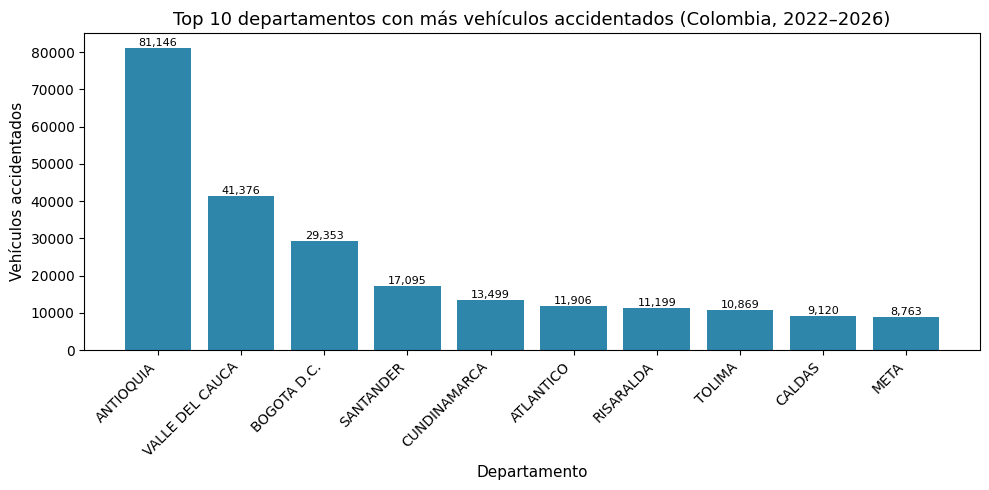

In [0]:
# ============================================================
# GRÁFICO 1 · BARRAS: TOP 10 DEPARTAMENTOS CON MÁS ACCIDENTES
# ============================================================
# Variables: DEPARTAMENTO_ACCIDENTE y SUM(total_registros) (tabla Gold).
import matplotlib.pyplot as plt

d = spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento, SUM(total_registros) AS vehiculos
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(d["departamento"], d["vehiculos"], color="#2E86AB")
ax.set_title("Top 10 departamentos con más vehículos accidentados (Colombia, 2022–2026)", fontsize=13)
ax.set_xlabel("Departamento", fontsize=11)
ax.set_ylabel("Vehículos accidentados", fontsize=11)
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(d["vehiculos"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

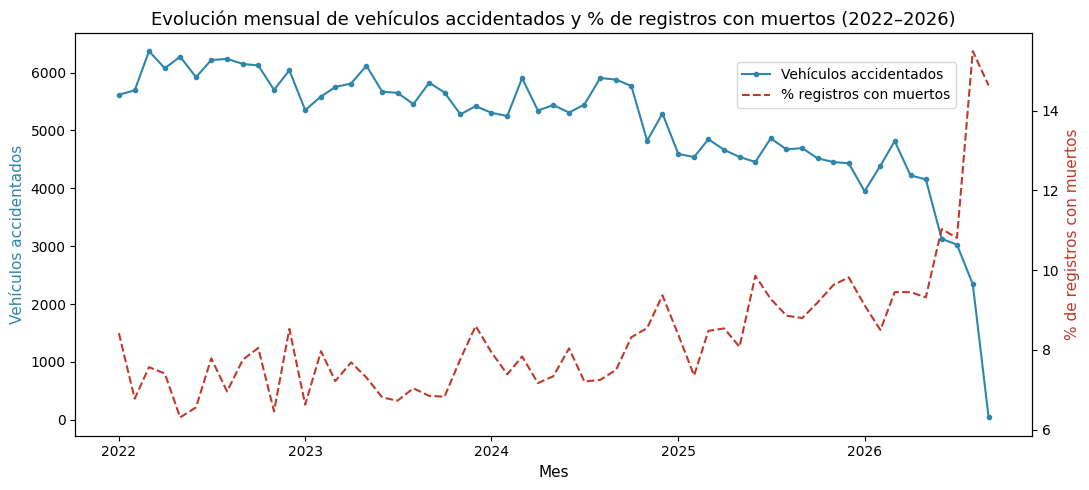

In [0]:
# ============================================================
# GRÁFICO 2 · LÍNEAS: EVOLUCIÓN MENSUAL DE ACCIDENTES (2022–2026)
# ============================================================
# Variables: fecha, total_registros y pct_registros_con_muertos
# (tabla gold_tendencia).
import matplotlib.pyplot as plt

t = spark.sql(f"""
    SELECT fecha, total_registros AS vehiculos, pct_registros_con_muertos
    FROM {TABLA_GOLD_TEND} ORDER BY fecha
""").toPandas()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(t["fecha"], t["vehiculos"], color="#2E86AB", marker="o", markersize=3, label="Vehículos accidentados")
ax1.set_title("Evolución mensual de vehículos accidentados y % de registros con muertos (2022–2026)", fontsize=13)
ax1.set_xlabel("Mes", fontsize=11)
ax1.set_ylabel("Vehículos accidentados", color="#2E86AB", fontsize=11)
ax2 = ax1.twinx()
ax2.plot(t["fecha"], t["pct_registros_con_muertos"], color="#C0392B", linestyle="--", label="% registros con muertos")
ax2.set_ylabel("% de registros con muertos", color="#C0392B", fontsize=11)
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout()
plt.show()

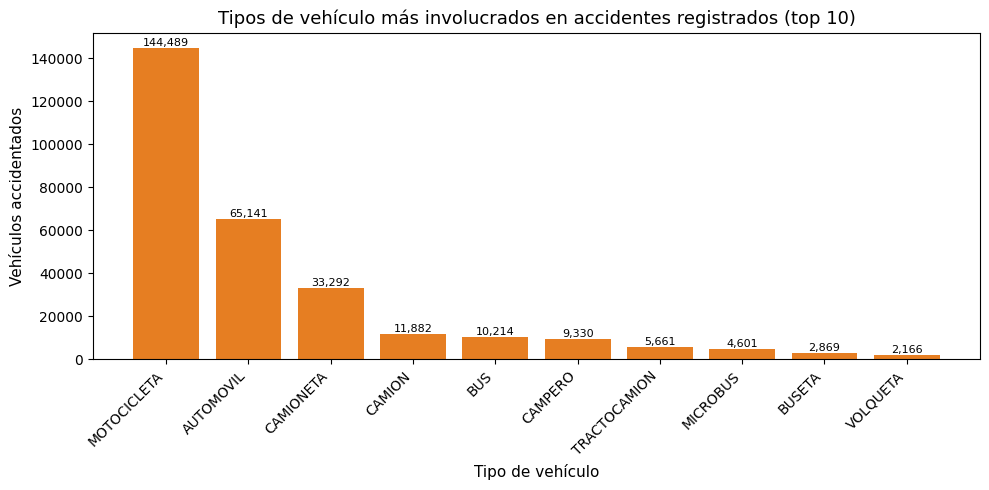

In [0]:
# ============================================================
# GRÁFICO 3 · BARRAS: TIPOS DE VEHÍCULO MÁS INVOLUCRADOS
# ============================================================
# Variables: TIPO_VEHICULO y SUM(total_registros) (tabla Gold).
import matplotlib.pyplot as plt

tv = spark.sql(f"""
    SELECT TIPO_VEHICULO AS tipo, SUM(total_registros) AS vehiculos
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(tv["tipo"], tv["vehiculos"], color="#E67E22")
ax.set_title("Tipos de vehículo más involucrados en accidentes registrados (top 10)", fontsize=13)
ax.set_xlabel("Tipo de vehículo", fontsize=11)
ax.set_ylabel("Vehículos accidentados", fontsize=11)
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(tv["vehiculos"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

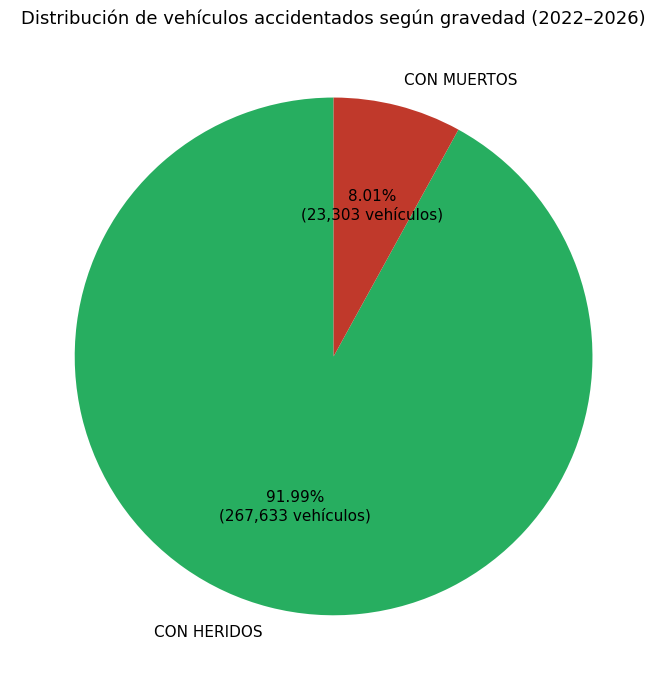

In [0]:
# ============================================================
# GRÁFICO 4 · CIRCULAR: DISTRIBUCIÓN SEGÚN GRAVEDAD DEL ACCIDENTE
# ============================================================
# Variables: GRAVEDAD_ACCIDENTE y SUM(total_registros) (tabla Gold).
import matplotlib.pyplot as plt

gr = spark.sql(f"""
    SELECT GRAVEDAD_ACCIDENTE AS gravedad, SUM(total_registros) AS vehiculos
    FROM {TABLA_GOLD} GROUP BY 1 ORDER BY 2 DESC
""").toPandas()

total_gr = int(gr["vehiculos"].sum())

def etiqueta(p):
    return f"{p:.2f}%\n({int(round(p * total_gr / 100)):,} vehículos)"

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(gr["vehiculos"], labels=gr["gravedad"], autopct=etiqueta,
       colors=["#27AE60", "#C0392B"], startangle=90, textprops={"fontsize": 11})
ax.set_title("Distribución de vehículos accidentados según gravedad (2022–2026)", fontsize=13)
plt.tight_layout()
plt.show()

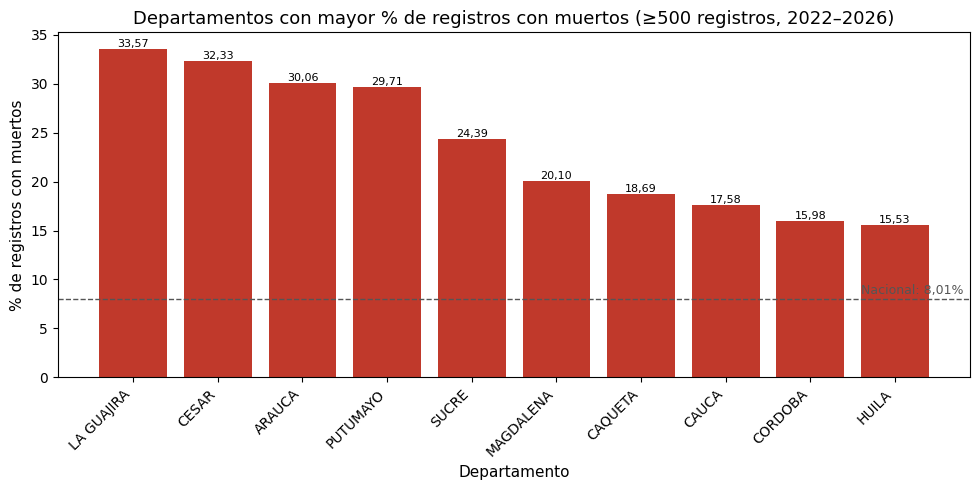

In [0]:
# ============================================================
# GRÁFICO 5 · BARRAS: REGISTROS CON PERSONAS FALLECIDAS POR DEPARTAMENTO
# ============================================================
# Variables: DEPARTAMENTO_ACCIDENTE y % de registros con muertos
# (composición de la gravedad, departamentos con ≥500 registros).
import matplotlib.pyplot as plt

md_ = spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_muertos
    FROM {TABLA_GOLD} GROUP BY 1
    HAVING SUM(total_registros) >= 500
    ORDER BY pct_muertos DESC LIMIT 10
""").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(md_["departamento"], md_["pct_muertos"], color="#C0392B")
ax.axhline(8.01, color="#555555", linestyle="--", linewidth=1)
ax.text(8.6, 8.5, "Nacional: 8,01%", fontsize=9, color="#555555")
ax.set_title("Departamentos con mayor % de registros con muertos (≥500 registros, 2022–2026)", fontsize=13)
ax.set_xlabel("Departamento", fontsize=11)
ax.set_ylabel("% de registros con muertos", fontsize=11)
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(md_["pct_muertos"]):
    ax.text(i, v, f"{v:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

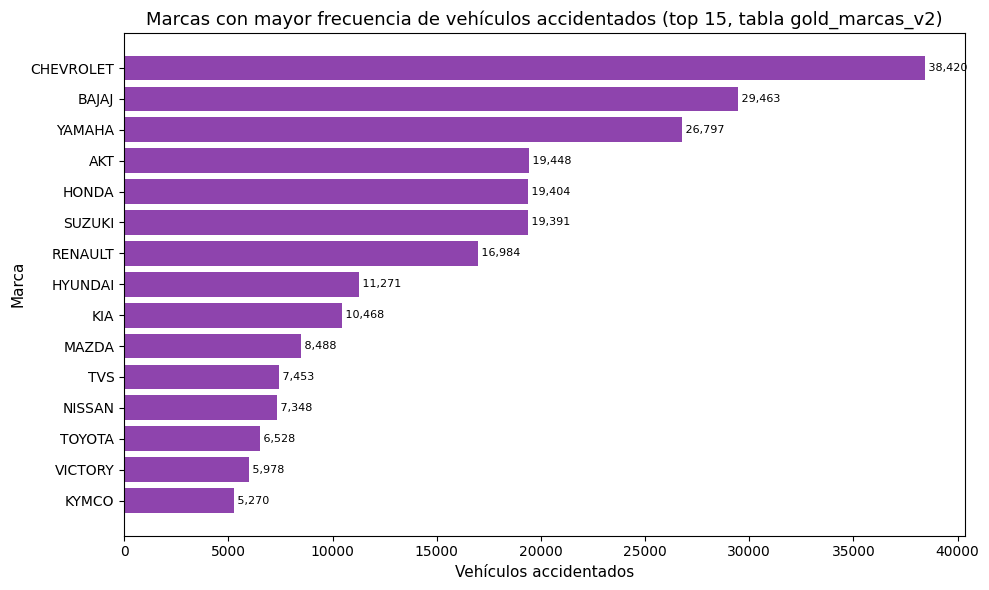

In [0]:
# ============================================================
# GRÁFICO 6 · BARRAS: MARCAS CON MAYOR FRECUENCIA DE REGISTROS
# ============================================================
# Variables: MARCA_VEHICULO y total_registros (tabla gold_marcas_v2,
# 380 marcas reales; sin el grupo NULL).
import matplotlib.pyplot as plt

mk = (spark.sql(f"""
    SELECT MARCA_VEHICULO AS marca, total_registros AS vehiculos
    FROM {TABLA_GOLD_MARCAS_V2}
    ORDER BY total_registros DESC LIMIT 15
""").toPandas().iloc[::-1])   # invertir para barras horizontales

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(mk["marca"], mk["vehiculos"], color="#8E44AD")
ax.set_title("Marcas con mayor frecuencia de vehículos accidentados (top 15, tabla gold_marcas_v2)", fontsize=13)
ax.set_xlabel("Vehículos accidentados", fontsize=11)
ax.set_ylabel("Marca", fontsize=11)
for i, v in enumerate(mk["vehiculos"]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

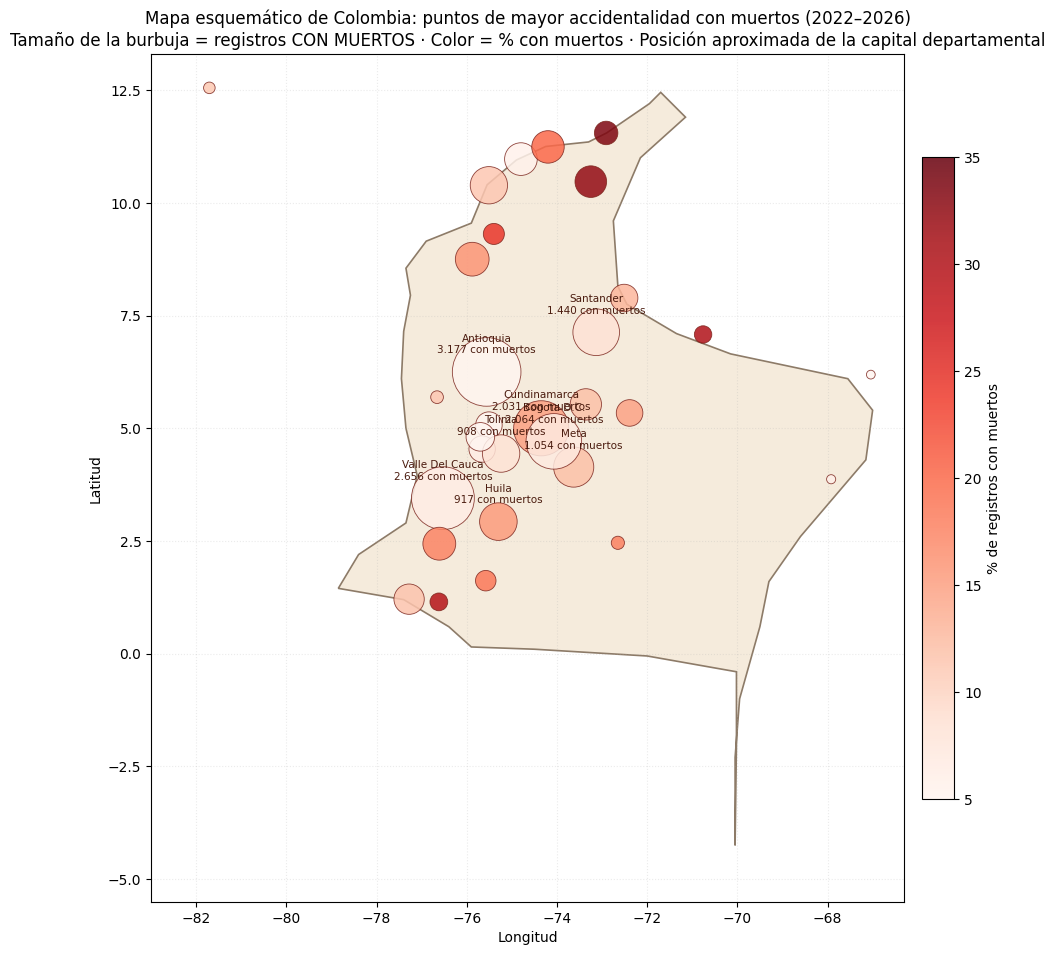

Interpretación: las burbujas más grandes marcan los departamentos con mayor número
absoluto de registros con muertos (concentración de la accidentalidad), mientras que
las burbujas de rojo más intenso indican mayor porcentaje de gravedad mortal dentro
de los registros de cada departamento. La posición de cada punto es aproximada.


In [0]:
# ============================================================
# GRÁFICO 7 · MAPA: PUNTOS DE MAYOR ACCIDENTALIDAD CON MUERTOS
# ============================================================
# La fuente NO trae coordenadas: cada departamento se ubica en la
# posición aproximada de su capital sobre una silueta simplificada
# de Colombia (mapa esquemático con fines ilustrativos).
#   · Tamaño de la burbuja  = registros CON MUERTOS (absoluto)
#   · Color de la burbuja   = % de registros con muertos
import matplotlib.pyplot as plt

mapa = spark.sql(f"""
    SELECT DEPARTAMENTO_ACCIDENTE AS departamento,
           SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END) AS registros_muertos,
           ROUND(100.0 * SUM(CASE WHEN GRAVEDAD_ACCIDENTE = 'CON MUERTOS' THEN total_registros ELSE 0 END)
                 / SUM(total_registros), 2) AS pct_muertos
    FROM {TABLA_GOLD}
    GROUP BY 1
""").toPandas()

CAPITALES = {  # (lat, lon) aproximadas de la capital departamental
    "AMAZONAS": (-4.21, -69.94), "ANTIOQUIA": (6.25, -75.56),
    "ARAUCA": (7.08, -70.76), "ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA": (12.55, -81.71),
    "ATLANTICO": (10.97, -74.80), "BOGOTA D.C.": (4.71, -74.07),
    "BOLIVAR": (10.39, -75.51), "BOYACA": (5.53, -73.36),
    "CALDAS": (5.07, -75.51), "CAQUETA": (1.62, -75.58),
    "CASANARE": (5.34, -72.39), "CAUCA": (2.44, -76.61),
    "CESAR": (10.47, -73.25), "CHOCO": (5.69, -76.66),
    "CORDOBA": (8.75, -75.88), "CUNDINAMARCA": (5.00, -74.35),
    "GUAINIA": (3.87, -67.92), "GUAVIARE": (2.46, -72.65),
    "HUILA": (2.93, -75.30), "LA GUAJIRA": (11.55, -72.91),
    "MAGDALENA": (11.24, -74.20), "META": (4.14, -73.63),
    "NARINO": (1.21, -77.28), "NORTE DE SANTANDER": (7.89, -72.51),
    "PUTUMAYO": (1.15, -76.62), "QUINDIO": (4.54, -75.66),
    "RISARALDA": (4.81, -75.70), "SANTANDER": (7.13, -73.13),
    "SUCRE": (9.31, -75.40), "TOLIMA": (4.44, -75.24),
    "VALLE DEL CAUCA": (3.45, -76.53), "VAUPES": (1.26, -70.24),
    "VICHADA": (6.19, -67.04),
}

sin_coord = sorted(set(mapa["departamento"]) - set(CAPITALES))
if sin_coord:
    print("⚠️ Departamentos sin coordenadas asignadas:", sin_coord)

m = mapa[mapa["departamento"].isin(CAPITALES)].copy()
m["lat"] = [CAPITALES[d][0] for d in m["departamento"]]
m["lon"] = [CAPITALES[d][1] for d in m["departamento"]]

# Silueta simplificada de Colombia (contorno aproximado; pares lon, lat)
silueta = [(-77.35, 8.55), (-76.9, 9.15), (-75.9, 9.55), (-75.55, 10.4),
           (-74.9, 10.95), (-74.25, 11.25), (-73.3, 11.35), (-72.9, 11.55),
           (-71.95, 12.2), (-71.7, 12.45), (-71.15, 11.9), (-72.15, 11.0),
           (-72.75, 9.6), (-72.65, 8.15), (-72.45, 7.75), (-71.35, 7.1),
           (-70.15, 6.65), (-67.55, 6.1), (-67.0, 5.4), (-67.15, 4.3),
           (-68.6, 2.6), (-69.3, 1.6), (-69.5, 0.6), (-69.95, -1.0),
           (-70.05, -2.3), (-70.05, -4.25), (-70.02, -2.0), (-70.02, -0.4),
           (-72.0, -0.05), (-74.5, 0.1), (-75.9, 0.15), (-76.4, 0.6),
           (-77.4, 1.2), (-78.85, 1.45), (-78.4, 2.2), (-77.35, 2.9),
           (-77.1, 3.95), (-77.35, 5.0), (-77.45, 6.1), (-77.4, 7.15),
           (-77.25, 7.95)]
sx, sy = zip(*silueta)

fig, ax = plt.subplots(figsize=(10, 11))
ax.fill(sx, sy, color="#F5EBDC", edgecolor="#8D7B68", linewidth=1.2, zorder=1)

sc = ax.scatter(m["lon"], m["lat"],
                s=40 + 2400 * m["registros_muertos"] / m["registros_muertos"].max(),
                c=m["pct_muertos"], cmap="Reds", vmin=5, vmax=35,
                alpha=0.85, edgecolor="#7B241C", linewidth=0.6, zorder=2)

for _, r in m.nlargest(8, "registros_muertos").iterrows():
    etiqueta = f"{r['departamento'].title()}\n{int(r['registros_muertos']):,} con muertos".replace(",", ".")
    ax.annotate(etiqueta, (r["lon"], r["lat"]), fontsize=7.5, ha="center",
                va="bottom", xytext=(0, 12), textcoords="offset points",
                color="#4A1B0E", zorder=3)

cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("% de registros con muertos", fontsize=10)

ax.set_title("Mapa esquemático de Colombia: puntos de mayor accidentalidad con muertos (2022–2026)\n"
             "Tamaño de la burbuja = registros CON MUERTOS · Color = % con muertos · Posición aproximada de la capital departamental",
             fontsize=12)
ax.set_xlabel("Longitud", fontsize=10)
ax.set_ylabel("Latitud", fontsize=10)
ax.set_xlim(-83, -66.3)
ax.set_ylim(-5.5, 13.3)
ax.grid(alpha=0.25, linestyle=":")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("Interpretación: las burbujas más grandes marcan los departamentos con mayor número")
print("absoluto de registros con muertos (concentración de la accidentalidad), mientras que")
print("las burbujas de rojo más intenso indican mayor porcentaje de gravedad mortal dentro")
print("de los registros de cada departamento. La posición de cada punto es aproximada.")

# CONCLUSIONES GENERALES DEL PROYECTO

**Proyecto:** Arquitectura Medallion para el análisis de la accidentalidad vial en Colombia — vehículos involucrados en accidentes de tránsito (Ley 2251 de 2022) · **Autoras:** Laura C. Arboleda (CC 1007286582) · Ana M. Echeverri (CC 1036627870)

Todas las afirmaciones siguientes están sustentadas en los resultados reales de las consultas ejecutadas en este notebook (Fases 3–6) y en el reporte de validación integral (17/17 comprobaciones superadas).

### 1. Arquitectura y calidad del dato

El patrón Medallion quedó implementado de extremo a extremo sobre Delta Lake y Unity Catalog: **Bronze** conservó los 450.335 registros crudos con trazabilidad de ingesta; **Silver** entregó 290.936 registros depurados — la reducción del 35,4% se explica exclusivamente por la deduplicación exacta de 159.399 filas, documentada en una tabla de auditoría (46.428 grupos), sin eliminación silenciosa de nulos ni outliers —; y **Gold** consolidó 4 tablas analíticas (principal, marcas, marcas_v2 y tendencia mensual) cuya agregación reconstruye Silver exactamente. La validación integral verificó integridad, ausencia de duplicados, tipos y formato en las 6 tablas del proyecto.

### 2. Patrones geográficos

La accidentalidad registrada está fuertemente concentrada: **ANTIOQUIA (27,89%), VALLE DEL CAUCA (14,22%) y BOGOTÁ D.C. (10,09%)** reúnen el 52,2% de los registros del país. En contraste, la composición de gravedad con muertos es mayor en departamentos de bajo o mediano volumen: **LA GUAJIRA (33,57%), CESAR (32,33%), ARAUCA (30,06%) y PUTUMAYO (29,71%)**, muy por encima del 8,01% nacional.

### 3. Tipos de vehículo y marcas

La **MOTOCICLETA** domina la frecuencia (144.489 vehículos, ~49,7% del total), seguida por AUTOMOVIL (65.141) y CAMIONETA (33.292). Sin embargo, la composición de gravedad con muertos se concentra en el transporte pesado: **TRACTOCAMIÓN (28,90%), VOLQUETA (19,67%) y CAMIÓN (18,46%)**. Por marca, la mayor frecuencia corresponde a **CHEVROLET (38.420 registros, 13,21% de los registros con marca)**, mientras que entre marcas con ≥1.000 registros las mayores composiciones con muertos son **KENWORTH (27,75%), SCANIA (22,86%) e INTERNATIONAL (22,62%)** — consistentemente marcas de carga pesada. **Precaución metodológica:** sin parque automotor (denominador de exposición) no puede afirmarse que una marca o tipo sea más propenso a accidentes mortales; los porcentajes describen la composición de la gravedad registrada.

### 4. Tendencias temporales

La frecuencia registrada desciende de forma sostenida — 72.402 (2022) → 67.556 (2023) → 65.651 (2024) → 55.264 (2025), y 30.063 en el 2026 parcial —, mientras que el porcentaje de registros con muertos **aumenta**: 7,38% (2022) → 8,85% (2025) → 10,03% (2026 parcial), con máximos en jun–ago de 2026 (11,03%, 10,81% y 15,49%) registrados con volúmenes muy inferiores; sep/2026 aporta solo 41 registros, evidencia de subregistro creciente al final del corte. Entre años completos, la estacionalidad mensual es estable (promedios de ~5.063 a ~5.717 vehículos por mes). La antigüedad muestra mayor frecuencia en vehículos de 0–5 años (110.446) y mayor composición con muertos en vehículos de más de 20 años (9,47%).

### 5. Gravedad y mortalidad

El 91,99% de los vehículos registrados corresponde a accidentes CON HERIDOS (267.633) y el 8,01% a CON MUERTOS (23.303) — aproximadamente 1 de cada 12 vehículos. Los focos de composición mortal se desplazan hacia departamentos de bajo volumen y hacia vehículos de carga pesada. Ninguna cifra de este notebook debe leerse como probabilidad o riesgo: la fuente no trae denominador de exposición (parque automotor ni flota circulante).

### 6. Limitaciones documentadas

* La fecha es mensual (sin día) y no existen coordenadas: el análisis temporal es año/mes y el geográfico es departamento/municipio.
* El grano es el vehículo involucrado, no el accidente: un mismo accidente aporta varias filas.
* No existe denominador de exposición, por lo que no se hacen afirmaciones de probabilidad.
* 2026 es un año parcial (corte septiembre) con signos de subregistro en los últimos meses.